# Занятие 7. Кинематика летающих роботов — демонстрации

Конспект: лекция 7 (разделы 7.1–7.9 и приложения 7.А–7.Г). Модуль `aerial.py`: углы 3-2-1, матрица $W$, кватернион и экспоненциальное обновление, пересчёт осей ROS и автопилота, матрица смешивания и распределение с насыщением и приоритетами, отказ мотора, плоскостность, простой и полный каскады управления, модель самолёта, пути Дубинса, комплементарные фильтры. Цвета — из `kinlib.py`.

**Обозначения** (как в конспекте и в `00_Паспорт/Обозначения.md`, раздел 2.8). Инерциальная система $Oxyz$ с осью $z$ вверх, связанные оси «вперёд — влево — вверх»; $\boldsymbol\Theta=(\varphi,\theta,\psi)^{\mathrm T}$ — крен, тангаж, рыскание, $R=R_z(\psi)R_y(\theta)R_x(\varphi)$, в коде `R321(psi, theta, phi)` (рыскание первым); $\boldsymbol\omega^b$, $\mathbf v^b$ — угловая и линейная скорости в связанных осях; $\dot{\boldsymbol\Theta}=W(\varphi,\theta)\boldsymbol\omega^b$; кватернион $\mathbf e=(e_0;\,e_1,e_2,e_3)$, скалярная часть первой. Квадрокоптер Hummingbird: $m=0{,}5$ кг, $L=0{,}175$ м, $d=L/\sqrt2$, $\kappa=k_M/k_F=0{,}0245$ м, $f_h=mg/4$, $f_{\max}=2f_h$; $\mathbf u=(T;\,\tau_x,\tau_y,\tau_z)=M\mathbf f$, $\varepsilon_i=+1$ — винт вращается против часовой стрелки при виде сверху, $Q_i=\kappa f_i$. Вектор тяги $\mathbf a_T=\ddot{\mathbf p}+g\mathbf z_0$, командное ускорение $\ddot{\mathbf p}_{\mathrm{cmd}}=\ddot{\mathbf p}^{\ast}+K_v(\dot{\mathbf p}^{\ast}-\dot{\mathbf p})+K_p(\mathbf p^{\ast}-\mathbf p)$, заданные величины — со звёздочкой. Самолёт: $\rho$ — радиус разворота, $\dot\psi=\omega_\psi$. Шаг интегрирования — $\Delta t$.

**Порядок величин в чужом коде.** `spatialmath.base.rpy2r(roll, pitch, yaw, order='zyx')` принимает углы в порядке «крен, тангаж, рыскание» — обратном нашему `R321(psi, theta, phi)`. `UnitQuaternion` хранит кватернион как $(w,x,y,z)$, а `scipy.spatial.transform.Rotation.as_quat` и `geometry_msgs/Quaternion` — как $(x,y,z,w)$. Якобианы `kinlib` и Robotics Toolbox идут в порядке $[\mathbf v;\boldsymbol\omega]$, в лекциях — $(\boldsymbol\omega;\mathbf v)$. Перед сравнением порядок проверяют на тестовом примере (демонстрации 1 и 2).

Демонстрации пронумерованы в порядке показа на занятии; каждая заканчивается числом или рисунком, которые совпадают с конспектом. Ячейка с ползунками (демонстрация 6) работает только при живом запуске; в сохранённом ноутбуке она показывает статичный кадр.

| № | Демонстрация | Конспект | Рисунок | Чем заканчивается |
|---|---|---|---|---|
| 1 | Матрица 3-2-1, пересчёт скорости и осей ENU/NED | § 7.2, примеры 7.1, 7.2; § 7.4, пример 7.4 | рис. 7.2 | $\dot{\mathbf p}=(4{,}29;\,2{,}08;\,-1{,}79)$ м/с; NED $(1;\,2;\,-3)$ м, курс $60^{\circ}$; сверка со `spatialmath` |
| 2 | Матрица $W$ и складывание рамок | § 7.3, пример 7.3 | рис. 7.3 | $\dot{\boldsymbol\Theta}=(0{,}707;\,0{,}085;\,0{,}701)$; $\lVert W\rVert_2=2{,}7/8{,}1/16{,}2/81$; $WR^{\mathrm T}J_\omega$ UR5e $=$ `rtb` |
| 3 | Счисление ориентации четырьмя способами | § 7.4 | рис. 7.4 | пять пиков $\lvert\theta\rvert$; ошибки $1{,}80^{\circ}$, $0{,}16^{\circ}$, $0{,}0002^{\circ}$; растяжение 6,2 % и 3,4 % |
| 4 | Матрица смешивания, насыщение и приоритеты | § 7.5, примеры 7.5, 7.6 | рис. 7.6, 7.7 | $\mathbf f=(1{,}02;\,1{,}23;\,1{,}43;\,1{,}23)$ Н; обрезание теряет крен; $s=0{,}753$; $\tau_z=0{,}1105$ Н·м |
| 5 | Отказ мотора: квадрокоптер и гексакоптер | § 7.5, прил. 7.В | — | ранг 3 и 4; мотор напротив выключен, запас 0 при любой $f_{\max}$; PPNNPN: 0,61/0,49 Н |
| 6 | Интерактив «наклон — ускорение» | § 7.6 | рис. 7.8 | ползунки $\psi,\theta,\varphi$: корпус, вектор тяги, горизонтальное ускорение |
| 7 | Дифференциальная плоскостность на окружности | § 7.6, пример 7.7, прил. 7.Б | — | наклон $4{,}6^{\circ}$, $T/mg=1{,}003$; $\boldsymbol\omega^b(1\ \mathrm{s})=(0{,}041;\,0{,}030;\,-0{,}0014)$ рад/с |
| 8 | Каскадное управление квадрокоптером | § 7.6, пример 7.8 | рис. 7.9 | 11,5° по оси и 16,1° полный наклон; $27{,}0^{\circ}$ и 5,51 Н против $29{,}2^{\circ}$; «сломай и посмотри» |
| 9 | Самолёт: координированный разворот и снос ветром | § 7.7, пример 7.9 | рис. 7.10 | $\rho=70{,}6$ м, $\dot\psi=0{,}283$ рад/с; 282 м при 40 м/с; курс $-17{,}5^{\circ}$, $V_g=19{,}1$ м/с; трохоида |
| 10 | Пути Дубинса | § 7.7, пример 7.10 | рис. 7.11 | LSL 636 м (LSR 794, RSL 1080, RSR 1225), LRL 395 м (RSR 717); `rtb.DubinsPlanner` — то же |
| 11 | Оценка ориентации | § 7.8, пример 7.11 | рис. 7.13 | дрейф $34^{\circ}$ за 60 с; фильтр: $0{,}28^{\circ}$, $\tau=0{,}49$ с; акселерометр показывает $(0;\,0;\,T/m)$ |

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt
from kinlib import NAVY, AMB, TEAL, RED, GREY, ICE, GREEN
import kinlib
from aerial import *
np.set_printoptions(precision=4, suppress=True)
warnings.filterwarnings('ignore')
%matplotlib inline
deg, rad = np.degrees, np.radians
wrap = lambda a: (np.asarray(a) + np.pi) % (2*np.pi) - np.pi
try:
    import roboticstoolbox as rtb               # только для сверок (демонстрации 1, 2, 10)
    from spatialmath import UnitQuaternion
    from spatialmath.base import rpy2r
except ImportError:
    rtb = None; print('roboticstoolbox не установлен: сверки с ним будут пропущены (pip install roboticstoolbox-python)')
try:
    from ipywidgets import interact, FloatSlider
except ImportError:
    interact = None; print('ipywidgets не установлен: интерактивная ячейка покажет только статичную картинку')

## 1. Матрица 3-2-1, пересчёт скорости и осей ENU/NED (§ 7.2, примеры 7.1, 7.2; § 7.4, пример 7.4)

$R=R_z(\psi)R_y(\theta)R_x(\varphi)$, $\dot{\mathbf p}=R\,\mathbf v^b$.
**Пример 7.2.** $\psi=30^{\circ}$, $\theta=10^{\circ}$, $\varphi=-20^{\circ}$, $\mathbf v^b=(5;\,0;\,-1)$ м/с. Ожидаем $\dot{\mathbf p}=(4{,}29;\ 2{,}08;\ -1{,}79)$ м/с, модуль $5{,}10$ м/с в обеих системах; вклад опущенного носа $-5\sin10^{\circ}=-0{,}87$ м/с. Напоминание о знаках: ось $y_b$ направлена влево, поэтому положительный тангаж **опускает** нос.

**Пример 7.1.** Уставка ROS в осях ENU $(2;\,1;\,3)$ м с курсом $30^{\circ}$ в осях автопилота NED: $(1;\,2;\,-3)$ м, курс $60^{\circ}$. Ориентация пересчитывается как $R'=P\,R\,F$ ($P$ — ENU→NED, $F$ — FLU→FRD); проверим, что при этом $\psi'=90^{\circ}-\psi$, $\theta'=-\theta$, $\varphi'=\varphi$.

**Сверка библиотекой** и **пример 7.4**: `rpy2r` с порядком аргументов «крен, тангаж, рыскание», кватернион `UnitQuaternion(R)` $=0{,}9437\langle-0{,}1893;\ 0{,}0381;\ 0{,}2685\rangle$ против порядка $(x,y,z,w)$ в `scipy`; кватернион $(0{,}707;\,0;\,0;\,0{,}707)$ даёт $R_z(90^{\circ})$, а $-\mathbf e$ — ту же матрицу.

Пример 7.2: R =
 [[ 0.853 -0.521 -0.03 ]
 [ 0.492  0.784  0.378]
 [-0.174 -0.337  0.925]]
ṗ = R v^b = [ 4.29  2.08 -1.79] м/с;  |v^b| = 5.10, |ṗ| = 5.10 м/с;  вклад опущенного носа −5·sin 10° = -0.87 м/с
ортогональность: max|RᵀR − E| = 2.2e-16, det R = 1.000000;  углы по матрице (ψ, θ, φ) = [ 30.  10. -20.] °

Пример 7.1: ENU (2; 1; 3) м  ->  NED [ 1.  2. -3.] м;  курс 30° от востока  ->  60° от севера
ориентация примера 7.2 в осях NED/FRD: ψ' = 60.0° (90° − 30°), θ' = -10.0° (−θ), φ' = -20.0° (φ)
1000 случайных ориентаций: max|ψ' − (90° − ψ)|, max|θ' + θ|, max|φ' − φ| = [0. 0. 0.] °

Сверка со spatialmath: rpy2r(φ, θ, ψ, order="zyx") − R321(ψ, θ, φ): max = 0.0e+00
  перепутанный порядок rpy2r(ψ, θ, φ): max|разность| = 0.899 — частая ошибка
  UnitQuaternion(R) =  0.9437 << -0.1893,  0.0381,  0.2685 >>  -> вектор (w, x, y, z): [ 0.9437 -0.1893  0.0381  0.2685]
  scipy Rotation.as_quat(): [-0.1893  0.0381  0.2685  0.9437]  — порядок (x, y, z, w)
  q2R(e) из aerial по кватерниону spatialm

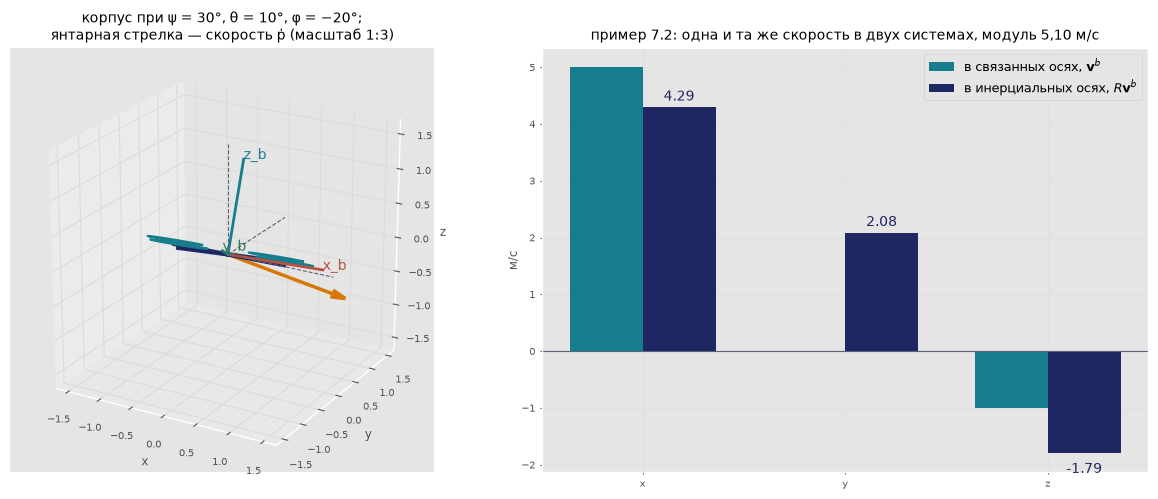

In [2]:
psi, th, ph = rad(30.0), rad(10.0), rad(-20.0)
R = R321(psi, th, ph); vb = np.array([5.0, 0.0, -1.0]); v = R.dot(vb)
print('Пример 7.2: R =\n', R.round(3))
print('ṗ = R v^b =', v.round(2), 'м/с;  |v^b| = %.2f, |ṗ| = %.2f м/с;  вклад опущенного носа −5·sin 10° = %.2f м/с' % (np.linalg.norm(vb), np.linalg.norm(v), -5*np.sin(th)))
print('ортогональность: max|RᵀR − E| = %.1e, det R = %.6f;  углы по матрице (ψ, θ, φ) =' % (np.abs(R.T.dot(R) - np.eye(3)).max(), np.linalg.det(R)), deg(np.array(euler321(R))).round(6), '°')

print('\nПример 7.1: ENU (2; 1; 3) м  ->  NED', enu_to_ned([2.0, 1.0, 3.0]), 'м;  курс 30° от востока  ->  %.0f° от севера' % deg(yaw_enu_to_ned(rad(30.0))))
e_ned = deg(np.array(euler321(R_to_ned_frd(R))))
print("ориентация примера 7.2 в осях NED/FRD: ψ' = %.1f° (90° − 30°), θ' = %.1f° (−θ), φ' = %.1f° (φ)" % tuple(e_ned))
rng = np.random.default_rng(1); err = np.zeros(3)
for _ in range(1000):
    a = rng.uniform([-np.pi, -1.4, -np.pi], [np.pi, 1.4, np.pi]); b = np.array(euler321(R_to_ned_frd(R321(*a))))
    err = np.maximum(err, np.abs(wrap(b - np.array([np.pi/2 - a[0], -a[1], a[2]]))))
print("1000 случайных ориентаций: max|ψ' − (90° − ψ)|, max|θ' + θ|, max|φ' − φ| =", deg(err).round(10), '°')

if rtb is not None:
    print('\nСверка со spatialmath: rpy2r(φ, θ, ψ, order="zyx") − R321(ψ, θ, φ): max = %.1e' % np.abs(rpy2r(ph, th, psi, order='zyx') - R).max())
    print('  перепутанный порядок rpy2r(ψ, θ, φ): max|разность| = %.3f — частая ошибка' % np.abs(rpy2r(psi, th, ph, order='zyx') - R).max())
    q_sm = UnitQuaternion(R); print('  UnitQuaternion(R) =', q_sm, ' -> вектор (w, x, y, z):', q_sm.vec.round(4))
    from scipy.spatial.transform import Rotation
    print('  scipy Rotation.as_quat():', Rotation.from_matrix(R).as_quat().round(4), ' — порядок (x, y, z, w)')
    print('  q2R(e) из aerial по кватерниону spatialmath совпадает с R: max|разность| = %.1e' % np.abs(q2R(q_sm.vec) - R).max())
e74 = np.array([np.cos(rad(45)), 0, 0, np.sin(rad(45))])
print('\nПример 7.4: e =', e74.round(3), '-> R =\n', q2R(e74).round(3), '\n  max|R(e) − R_z(90°)| = %.1e;  max|R(−e) − R(e)| = %.1e (двойное покрытие)' % (np.abs(q2R(e74) - Rz(rad(90))).max(), np.abs(q2R(-e74) - q2R(e74)).max()))

fig = plt.figure(figsize=(12.5, 5.0))
ax = fig.add_subplot(1, 2, 1, projection='3d'); draw_quad(ax, R); ax.view_init(22, -60)
ax.quiver(0, 0, 0, *(v/3.0), color=AMB, lw=2.5, arrow_length_ratio=0.12)
ax.set_title('корпус при ψ = 30°, θ = 10°, φ = −20°;\nянтарная стрелка — скорость ṗ (масштаб 1:3)', fontsize=10)
ax = fig.add_subplot(1, 2, 2); w_ = 0.36; k = np.arange(3)
ax.bar(k - w_/2, vb, w_, color=TEAL, label='в связанных осях, $\\mathbf{v}^b$'); ax.bar(k + w_/2, v, w_, color=NAVY, label='в инерциальных осях, $R\\mathbf{v}^b$')
for i in range(3): ax.text(i + w_/2, v[i] + (0.12 if v[i] > 0 else -0.35), '%.2f' % v[i], ha='center', fontsize=10, color=NAVY)
ax.set_xticks(k); ax.set_xticklabels(['x', 'y', 'z']); ax.axhline(0, color=GREY, lw=.8); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_ylabel('м/с')
ax.set_title('пример 7.2: одна и та же скорость в двух системах, модуль 5,10 м/с', fontsize=10)
plt.tight_layout(); plt.show()

## 2. Матрица $W$ и складывание рамок (§ 7.3, пример 7.3)

$\dot{\boldsymbol\Theta}=W(\varphi,\theta)\,\boldsymbol\omega^b=W(\varphi,\theta)R^{\mathrm T}\boldsymbol\omega$; определитель прямой матрицы равен $\cos\theta$.
**Пример 7.3.** $\boldsymbol\omega^b=(0{,}1;\,0{,}2;\,0{,}3)$ рад/с, $\varphi=20^{\circ}$. Ожидаем при $\theta=60^{\circ}$: $\dot{\boldsymbol\Theta}=(0{,}707;\ 0{,}085;\ 0{,}701)$ рад/с; при $85^{\circ}$: $\dot\varphi=4{,}10$, $\dot\psi=4{,}02$ рад/с; спектральная норма $W$ равна $2{,}7;\ 8{,}1;\ 16{,}2;\ 81$ при $60^{\circ}, 80^{\circ}, 85^{\circ}, 89^{\circ}$ и не превышает $1{,}7$ при крене и тангаже до $40^{\circ}$.

Затем проверим формулу численным дифференцированием углов: повернём тело на малый угол с угловой скоростью $\boldsymbol\omega$, заданной в **неподвижной** системе, и сравним приращения углов с $WR^{\mathrm T}\boldsymbol\omega$ и с ошибочным $W\boldsymbol\omega$.
Наконец, **связь с аналитическим якобианом** (§ 7.3): у UR5e (`kinlib.make_ur5e`, официальная таблица ДХ) угловой блок аналитического якобиана для углов 3-2-1 равен $W(\varphi,\theta)R^{\mathrm T}J_\omega$; сверяем его с `jacob0_analytical(q, representation='rpy/zyx')` из Robotics Toolbox.

W(20°, 60°) =
 [[ 1.     0.592  1.628]
 [ 0.     0.94  -0.342]
 [ 0.     0.684  1.879]]
проверка: W·Wdirect = E, max ошибка 8.8e-17;  det Wdirect = 0.5000 = cos 60°

 тангаж |   dφ/dt   dθ/dt   dψ/dt, рад/с | ‖W‖₂
    0°  |   0.100   0.085   0.350          |    1.0
   30°  |   0.302   0.085   0.405          |    1.4
   60°  |   0.707   0.085   0.701          |    2.7
   80°  |   2.087   0.085   2.017          |    8.1
   85°  |   4.104   0.085   4.019          |   16.2
   89°  |  20.169   0.085  20.072          |   81.0


наибольшая ‖W‖₂ при |φ|, |θ| ≤ 40°: 1.67

численное дифференцирование углов (200 случайных поз, |θ| < 75°): max|Θ̇ − W Rᵀ ω| = 2.3e-05,  max|Θ̇ − W ω| = 9.83 рад/с

UR5e, q = (20, −70, 100, −120, −60, 30)°: углы схвата (φ, θ, ψ) = (163.9; 25.7; 76.3)°
  W Rᵀ J_ω против конечных разностей углов: max|разность| = 9.0e-08 (в единицах dq)
  rtb.jacob0_analytical(q, "rpy/zyx"): угловой блок − W Rᵀ J_ω = 3.3e-16;  линейный блок − J_v = 3.3e-16
  если забыть Rᵀ (взять W J_ω): max|разность| = 2.07


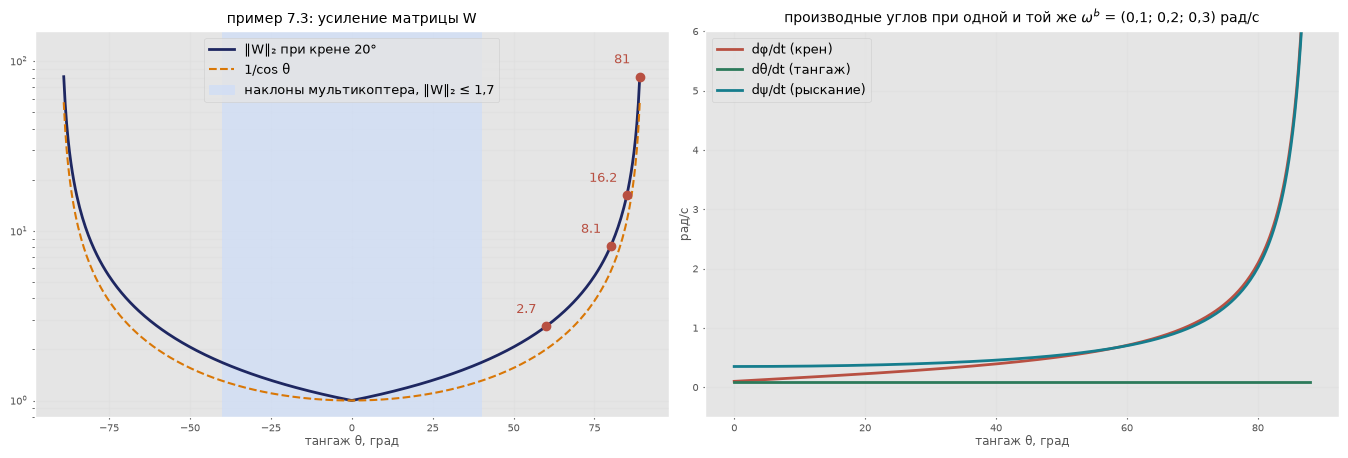

In [3]:
w = np.array([0.1, 0.2, 0.3]); ph = rad(20.0)
print('W(20°, 60°) =\n', Wmat(ph, rad(60)).round(3))
print('проверка: W·Wdirect = E, max ошибка %.1e;  det Wdirect = %.4f = cos 60°' % (np.abs(Wmat(ph, rad(60)).dot(Wdirect(ph, rad(60))) - np.eye(3)).max(), np.linalg.det(Wdirect(ph, rad(60)))))
print('\n тангаж |   dφ/dt   dθ/dt   dψ/dt, рад/с | ‖W‖₂')
for t in (0, 30, 60, 80, 85, 89):
    r = Wmat(ph, rad(t)).dot(w); print('  %3d°  | %7.3f %7.3f %7.3f          | %6.1f' % (t, r[0], r[1], r[2], np.linalg.norm(Wmat(ph, rad(t)), 2)))
print('наибольшая ‖W‖₂ при |φ|, |θ| ≤ 40°: %.2f' % max(np.linalg.norm(Wmat(rad(a), rad(b)), 2) for a in range(-40, 41) for b in range(-40, 41)))

rng = np.random.default_rng(3); e_ok = e_bad = 0.0; dt = 1e-6
for _ in range(200):
    ang = rng.uniform([-np.pi, -1.3, -np.pi], [np.pi, 1.3, np.pi]); Rk = R321(*ang); wk = rng.normal(size=3)
    d = wrap(np.array(euler321(expm_so3(wk*dt).dot(Rk))) - ang)[::-1]/dt      # (dφ, dθ, dψ)/dt численно
    e_ok = max(e_ok, np.abs(d - Wmat(ang[2], ang[1]).dot(Rk.T.dot(wk))).max()); e_bad = max(e_bad, np.abs(d - Wmat(ang[2], ang[1]).dot(wk)).max())
print('\nчисленное дифференцирование углов (200 случайных поз, |θ| < 75°): max|Θ̇ − W Rᵀ ω| = %.1e,  max|Θ̇ − W ω| = %.2f рад/с' % (e_ok, e_bad))

ur = kinlib.make_ur5e(); q = rad([20.0, -70.0, 100.0, -120.0, -60.0, 30.0]); ur.forward(q)
J = ur.jacobian; Te = ur.end_frame.t_4_4; Re = Te[:3, :3]; ps_, th_, ph_ = euler321(Re)
JA_w = Wmat(ph_, th_).dot(Re.T).dot(J[3:6])                 # угловой блок аналитического якобиана, строки (φ, θ, ψ)
print('\nUR5e, q = (20, −70, 100, −120, −60, 30)°: углы схвата (φ, θ, ψ) = (%.1f; %.1f; %.1f)°' % tuple(deg([ph_, th_, ps_])))
dq = rng.normal(size=6)*1e-7; ur.forward(q + dq); R2 = ur.end_frame.t_4_4[:3, :3]; ur.forward(q)
d_num = wrap(np.array(euler321(R2)) - np.array([ps_, th_, ph_]))[::-1]
print('  W Rᵀ J_ω против конечных разностей углов: max|разность| = %.1e (в единицах dq)' % (np.abs(d_num - JA_w.dot(dq)).max()/np.abs(dq).max()))
if rtb is not None:
    rob = rtb.DHRobot([rtb.RevoluteDH(d=r_[0], a=r_[1], alpha=r_[2], offset=r_[3]) for r_ in kinlib.UR5E_DH])
    JA = rob.jacob0_analytical(q, representation='rpy/zyx')    # порядок rtb: [v; Θ̇]
    print('  rtb.jacob0_analytical(q, "rpy/zyx"): угловой блок − W Rᵀ J_ω = %.1e;  линейный блок − J_v = %.1e' % (np.abs(JA[3:] - JA_w).max(), np.abs(JA[:3] - J[:3]).max()))
    print('  если забыть Rᵀ (взять W J_ω): max|разность| = %.2f' % np.abs(JA[3:] - Wmat(ph_, th_).dot(J[3:6])).max())

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.6))
tt = np.linspace(-89, 89, 400); ax = axs[0]
ax.semilogy(tt, [np.linalg.norm(Wmat(ph, rad(t)), 2) for t in tt], color=NAVY, lw=2, label='‖W‖₂ при крене 20°')
ax.semilogy(tt, 1/np.cos(rad(tt)), color=AMB, lw=1.5, ls='--', label='1/cos θ')
for t in (60, 80, 85, 89):
    n_ = np.linalg.norm(Wmat(ph, rad(t)), 2); ax.plot(t, n_, 'o', color=RED); ax.text(t - 3, n_*1.2, '%.1f' % n_ if n_ < 50 else '%.0f' % n_, color=RED, ha='right', fontsize=9)
ax.axvspan(-40, 40, color=ICE, alpha=.6, label='наклоны мультикоптера, ‖W‖₂ ≤ 1,7')
ax.set_ylim(0.8, 150); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=9, loc='upper center'); ax.set_xlabel('тангаж θ, град'); ax.set_title('пример 7.3: усиление матрицы W', fontsize=10)
td = np.linspace(0, 88, 300); rates = np.array([Wmat(ph, rad(t)).dot(w) for t in td]); ax = axs[1]
for j, (c, n_) in enumerate(((RED, 'dφ/dt (крен)'), (GREEN, 'dθ/dt (тангаж)'), (TEAL, 'dψ/dt (рыскание)'))): ax.plot(td, rates[:, j], color=c, lw=2, label=n_)
ax.set_ylim(-0.5, 6); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('тангаж θ, град'); ax.set_ylabel('рад/с')
ax.set_title('производные углов при одной и той же $\\omega^b$ = (0,1; 0,2; 0,3) рад/с', fontsize=10)
plt.tight_layout(); plt.show()

## 3. Счисление ориентации четырьмя способами (§ 7.4)

Манёвр «кувырок» — вращение на месте с непрерывным опусканием носа: $\boldsymbol\omega^b(t)=(0{,}2\sin1{,}3t;\ 0{,}8;\ 0{,}1\cos t)$ рад/с, шаг $\Delta t=0{,}01$ с, 20 с. Методом Эйлера первого порядка: углы $\boldsymbol\Theta\leftarrow\boldsymbol\Theta+\Delta t\,W\boldsymbol\omega^b$; матрица $R\leftarrow R(E+\Delta t\,\Lambda(\boldsymbol\omega^b))$ с ортогонализацией через сингулярное разложение; кватернион $\mathbf e\leftarrow\mathbf e+\frac{\Delta t}2\mathbf e\otimes\boldsymbol\omega^b$ с нормировкой. Четвёртый способ — экспоненциальное обновление $R\leftarrow R\exp(\Delta t\,\Lambda(\boldsymbol\omega^b))$ с угловой скоростью в начале и в середине шага. Эталон — экспоненциальное обновление с шагом в 20 раз меньше.

Ожидаем: $\lvert\theta\rvert$ пять раз превышает $70^{\circ}$ (78,7; 74,4; 81,9; 73,1; 89,7°), к особенности близко подходит только последний пик при $t=18$ с; ошибка углов до $1{,}80^{\circ}$, матрицы и кватерниона — $0{,}16^{\circ}$, экспоненты с $\boldsymbol\omega$ в начале шага — тоже $0{,}16^{\circ}$, с $\boldsymbol\omega$ в середине шага — $0{,}0002^{\circ}$. Без коррекции за 20 с матрица растягивает векторы на $\sigma_{\max}-1=6{,}2$ %, а квадрат нормы кватерниона растёт на $\lVert\mathbf e\rVert^2-1=3{,}4$ %: ровно настолько растягивает векторы поворот $\mathbf v\mapsto\mathbf e\otimes\mathbf v\otimes\bar{\mathbf e}$ (однородная форма `q2R_h`). Формула $R(\mathbf e)$ из конспекта (`q2R`) верна только при $\lVert\mathbf e\rVert=1$; с ненормированным кватернионом она растягивает векторы на 6,8 %.

наибольшая ошибка, град:  углы 1.80 (t = 7.42 с) | матрица 0.16 | кватернион 0.16 | экспонента, ω в начале шага 0.16 | ω в середине шага 0.0002
без коррекции за 20 с:  σ_max(R) − 1 = 6.2 %,  ‖e‖² − 1 = 3.4 %  (прежние меры: ‖RᵀR − E‖_F = 0.18, |‖e‖ − 1| = 0.017)
ненормированный кватернион к 20 с: σ_max − 1 у q2R (формула конспекта) = 6.8 %, у q2R_h = 3.4 % = ‖e‖² − 1
пики |θ| эталона, град: [78.7 74.4 81.9 73.1 89.7]  в моменты [ 1.9  6.   9.9 14.1 18. ] с


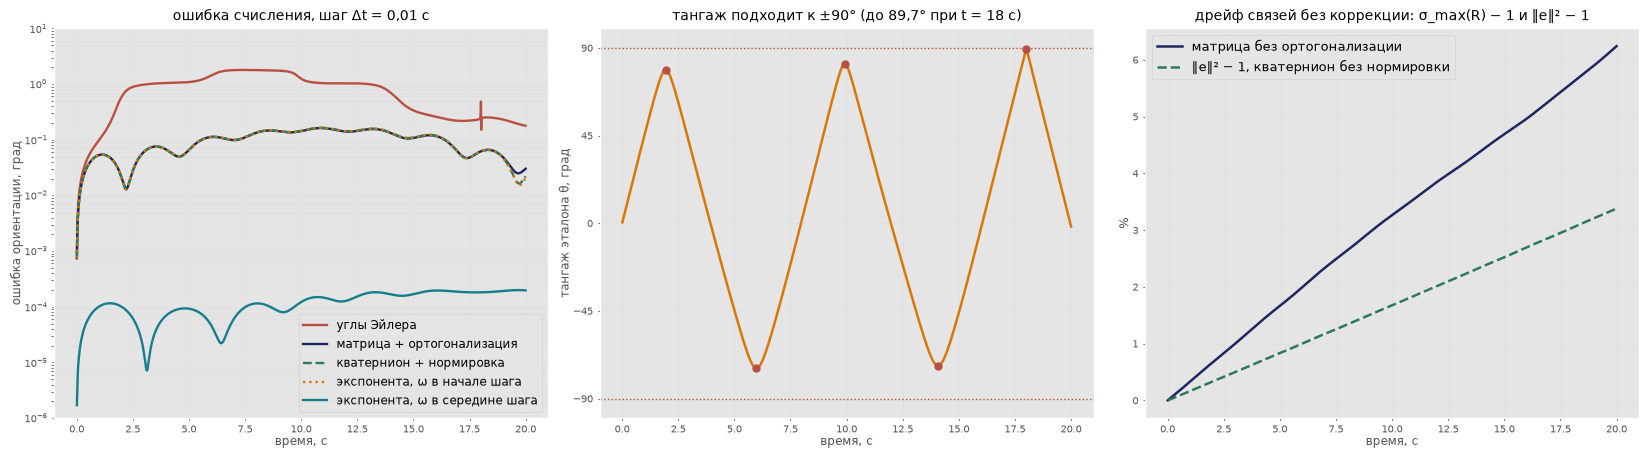

In [4]:
o = integrate_orientation(h=0.01, T=20.0, sub=20)
i_e = np.argmax(o[:, 2])
print('наибольшая ошибка, град:  углы %.2f (t = %.2f с) | матрица %.2f | кватернион %.2f | экспонента, ω в начале шага %.2f | ω в середине шага %.4f'
      % (o[:, 2].max(), o[i_e, 0], o[:, 3].max(), o[:, 4].max(), o[:, 7].max(), o[:, 8].max()))
print('без коррекции за 20 с:  σ_max(R) − 1 = %.1f %%,  ‖e‖² − 1 = %.1f %%  (прежние меры: ‖RᵀR − E‖_F = %.2f, |‖e‖ − 1| = %.3f)' % (100*o[-1, 9], 100*o[-1, 10], o[-1, 5], o[-1, 6]))
qn = np.array([1.0, 0, 0, 0])
for i_ in range(2000):
    qn = qn + 0.5 * 0.01 * qmul(qn, np.r_[0, omega_loop(i_ * 0.01)])
print('ненормированный кватернион к 20 с: σ_max − 1 у q2R (формула конспекта) = %.1f %%, у q2R_h = %.1f %% = ‖e‖² − 1'
      % (100*(np.linalg.svd(q2R(qn), compute_uv=False)[0] - 1), 100*(np.linalg.svd(q2R_h(qn), compute_uv=False)[0] - 1)))
a_ = np.abs(o[:, 1]); pk =[i for i in range(1, len(a_) - 1) if a_[i] >= a_[i-1] and a_[i] >= a_[i+1] and a_[i] > 70]
print('пики |θ| эталона, град:', a_[pk].round(1), ' в моменты', o[pk, 0].round(1), 'с')

fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.6)); ax = axs[0]
for j, c, n_, ls in ((2, RED, 'углы Эйлера', '-'), (3, NAVY, 'матрица + ортогонализация', '-'), (4, GREEN, 'кватернион + нормировка', '--'),
                     (7, AMB, 'экспонента, ω в начале шага', ':'), (8, TEAL, 'экспонента, ω в середине шага', '-')):
    ax.semilogy(o[:, 0], np.maximum(o[:, j], 1e-7), color=c, lw=1.7, ls=ls, label=n_)
ax.set_ylim(1e-6, 10); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8.5, loc='lower right'); ax.set_xlabel('время, с'); ax.set_ylabel('ошибка ориентации, град')
ax.set_title('ошибка счисления, шаг Δt = 0,01 с', fontsize=10)
ax = axs[1]; ax.plot(o[:, 0], o[:, 1], color=AMB, lw=1.8); ax.axhline(90, color=RED, ls=':', lw=1); ax.axhline(-90, color=RED, ls=':', lw=1)
ax.plot(o[pk, 0], o[pk, 1], 'o', color=RED, ms=5)
ax.set_ylim(-100, 100); ax.set_yticks([-90, -45, 0, 45, 90]); ax.set_ylabel('тангаж эталона θ, град'); ax.set_xlabel('время, с'); ax.grid(alpha=.3)
ax.set_title('тангаж подходит к ±90° (до 89,7° при t = 18 с)', fontsize=10)
ax = axs[2]; ax.plot(o[:, 0], 100*o[:, 9], color=NAVY, lw=1.8, label='матрица без ортогонализации'); ax.plot(o[:, 0], 100*o[:, 10], color=GREEN, lw=1.8, ls='--', label='‖e‖² − 1, кватернион без нормировки')
ax.grid(alpha=.3); ax.legend(fontsize=9, loc='upper left'); ax.set_xlabel('время, с'); ax.set_ylabel('%'); ax.set_title('дрейф связей без коррекции: σ_max(R) − 1 и ‖e‖² − 1', fontsize=10)
plt.tight_layout(); plt.show()

## 4. Матрица смешивания, насыщение и приоритеты (§ 7.5, примеры 7.5, 7.6)

$\mathbf u=M\mathbf f$; строки $M$ схемы «X» ортогональны, $MM^{\mathrm T}=D=\operatorname{diag}(4,4d^2,4d^2,4\kappa^2)$, поэтому $M^{-1}=M^{\mathrm T}D^{-1}$.
**Пример 7.5.** $\mathbf u=(4{,}905;\ 0{,}05;\ 0;\ 0{,}01)$: поправки $\tau_x/(4d)=0{,}101$ Н и $\tau_z/(4\kappa)=0{,}102$ Н, тяги $\mathbf f=(1{,}02;\ 1{,}23;\ 1{,}43;\ 1{,}23)$ Н. Пределы моментов в висении $4df_h=0{,}61$ и $4\kappa f_h=0{,}12$ Н·м; достижимые пары $(\tau_x,\tau_z)$ при $T=mg$, $\tau_y=0$ — ромб.

**Пример 7.6 (главный случай насыщения).** Запрос $\mathbf u=(4{,}905;\ 0{,}05;\ 0;\ 0{,}15)$ вне ромба, $M^{-1}\mathbf u=(-0{,}40;\ -0{,}20;\ 2{,}85;\ 2{,}65)$ Н. Сравниваем три способа: (1) покомпонентное обрезание — $M\mathbf f=(4{,}905;\ 0;\ 0;\ 0{,}12)$, **крен потерян**; (2) масштабирование моментов при сохранённой тяге — $s=0{,}753$; (3) приоритеты «крен и тангаж → тяга → рыскание» — крен сохранён, $\tau_z=0{,}1105$ Н·м, $\mathbf f=(0;\ 0{,}20;\ 2{,}45;\ 2{,}25)$ Н. Масштабировать весь $\mathbf u$ вместе с тягой нельзя: допустимо только $s=0$. Второй запрос $(4{,}905;\ 0{,}3;\ 0{,}2;\ 0{,}1)$: обрезание даёт $(5{,}707;\ 0{,}201;\ 0{,}101;\ 0{,}080)$ — лишние 16 % тяги. Для сравнения — постановка Дарема через `scipy.optimize.lsq_linear` с весами каналов (`allocate_weighted`).

d = L/√2 = 0.1237 м, κ = k_M/k_F = 0.0245 м, f_h = 1.226 Н, f_max = 2.45 Н, обороты висения 4480 об/мин
M =
 [[ 1.      1.      1.      1.    ]
 [-0.1237  0.1237  0.1237 -0.1237]
 [-0.1237  0.1237 -0.1237  0.1237]
 [-0.0245 -0.0245  0.0245  0.0245]] 
M Mᵀ = diag [4.     0.0612 0.0612 0.0024] ;  вне диагонали max = 1.9e-20;  Mᵀ D⁻¹ = M⁻¹: True

Пример 7.5: поправки τ_x/(4d) = 0.101 Н, τ_z/(4κ) = 0.102 Н;  f = M⁻¹u = [1.02 1.23 1.43 1.23] Н, сумма 4.905 Н
пределы в висении: τ_x = 4 d f_h = 0.61 Н·м, τ_z = 4 κ f_h = 0.12 Н·м

Пример 7.6: запрос u = [4.905 0.05  0.    0.15 ] ;  M⁻¹u = [-0.4  -0.2   2.85  2.65] Н
  (1) обрезание:            f = [0.   0.   2.45 2.45]  M f = [4.905 0.    0.    0.12 ]  -> КРЕН ПОТЕРЯН (0,05 -> 0.000), рыскание на пределе
  (2) масштабирование моментов: s = 0.753,  f = [0.   0.15 2.45 2.3 ]  M f = [4.905 0.038 0.    0.113]
  (3) приоритеты:           f = [0.   0.2  2.45 2.25]  M f = [4.905  0.05   0.     0.1105]  (предел рыскания 0.1204·(1 − 0,05/0.607) = 0.110

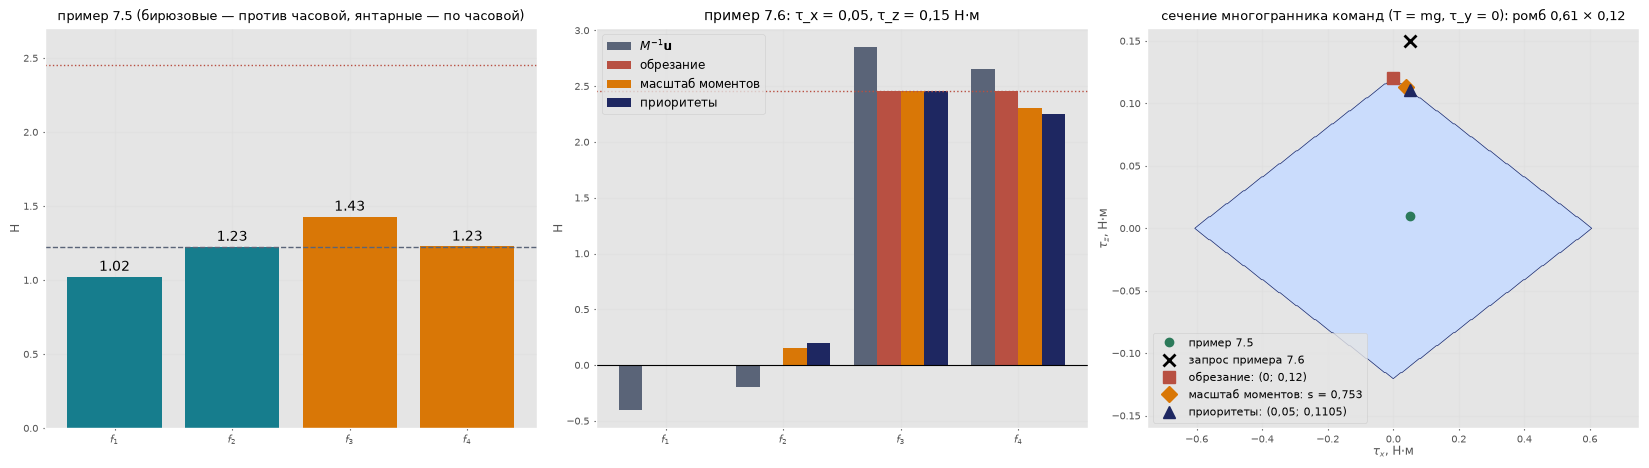

In [5]:
M = mixer_x(); Mi = mixer_x_inv(); W_ = M_Q*G
print('d = L/√2 = %.4f м, κ = k_M/k_F = %.4f м, f_h = %.3f Н, f_max = %.2f Н, обороты висения %.0f об/мин' % (D_Q, KAPPA, F_HOVER, F_MAX, np.sqrt(F_HOVER/K_F)))
print('M =\n', M.round(4), '\nM Mᵀ = diag', np.diag(M.dot(M.T)).round(5), ';  вне диагонали max = %.1e;  Mᵀ D⁻¹ = M⁻¹: %s' % (np.abs(M.dot(M.T) - np.diag(np.diag(M.dot(M.T)))).max(), np.allclose(Mi, np.linalg.inv(M))))
u = np.array([W_, 0.05, 0.0, 0.01]); f75 = Mi.dot(u)
print('\nПример 7.5: поправки τ_x/(4d) = %.3f Н, τ_z/(4κ) = %.3f Н;  f = M⁻¹u =' % (u[1]/(4*D_Q), u[3]/(4*KAPPA)), f75.round(2), 'Н, сумма %.3f Н' % f75.sum())
tx_max, tz_max = 4*D_Q*F_HOVER, 4*KAPPA*F_HOVER
print('пределы в висении: τ_x = 4 d f_h = %.2f Н·м, τ_z = 4 κ f_h = %.2f Н·м' % (tx_max, tz_max))

u6 = np.array([W_, 0.05, 0.0, 0.15])
f_raw, f_clip, u_clip = allocate(u6); s_m, f_sm, u_sm = allocate_scale_moments(u6); f_pr, u_pr = allocate_priority(u6); s_all = allocate_scale_all(u6)[0]
f_w, u_w = allocate_weighted(u6)
print('\nПример 7.6: запрос u =', u6.round(3), ';  M⁻¹u =', f_raw.round(2), 'Н')
print('  (1) обрезание:            f =', f_clip.round(2) + 0.0, ' M f =', u_clip.round(3) + 0.0, ' -> КРЕН ПОТЕРЯН (0,05 -> %.3f), рыскание на пределе' % u_clip[1])
print('  (2) масштабирование моментов: s = %.3f,  f =' % s_m, f_sm.round(2) + 0.0, ' M f =', u_sm.round(3) + 0.0)
print('  (3) приоритеты:           f =', f_pr.round(2) + 0.0, ' M f =', u_pr.round(4) + 0.0, ' (предел рыскания %.4f·(1 − 0,05/%.3f) = %.4f Н·м)' % (tz_max, tx_max, tz_max*(1 - 0.05/tx_max)))
print('  масштабирование всего u вместе с тягой: s = %.3f' % abs(s_all))
print('  Дарем (lsq_linear, веса 10:10:10:1): f =', f_w.round(2) + 0.0, ' M f =', u_w.round(4) + 0.0)
u2 = np.array([W_, 0.3, 0.2, 0.1])
print('\nЗапрос (4,905; 0,3; 0,2; 0,1): обрезание M f =', allocate(u2)[2].round(3), '(тяга +%.0f %%);  приоритеты M f =' % (100*(allocate(u2)[2][0]/W_ - 1)), allocate_priority(u2)[1].round(3))

fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.7)); k = np.arange(4); ax = axs[0]
ax.bar(k, f75, color=[TEAL, TEAL, AMB, AMB]); ax.axhline(F_HOVER, color=GREY, ls='--', lw=1); ax.axhline(F_MAX, color=RED, ls=':', lw=1)
for i in range(4): ax.text(i, f75[i] + 0.04, '%.2f' % f75[i], ha='center', fontsize=10)
ax.set_xticks(k); ax.set_xticklabels(['$f_1$', '$f_2$', '$f_3$', '$f_4$']); ax.set_ylabel('Н'); ax.set_ylim(0, 2.7); ax.grid(alpha=.3)
ax.set_title('пример 7.5 (бирюзовые — против часовой, янтарные — по часовой)', fontsize=9.5)
ax = axs[1]; ww = 0.2
for j, (ff, c, n_) in enumerate(((f_raw, GREY, '$M^{-1}\\mathbf{u}$'), (f_clip, RED, 'обрезание'), (f_sm, AMB, 'масштаб моментов'), (f_pr, NAVY, 'приоритеты'))):
    ax.bar(k + (j - 1.5)*ww, ff, ww, color=c, label=n_)
ax.axhline(0, color='k', lw=.8); ax.axhline(F_MAX, color=RED, ls=':', lw=1); ax.set_xticks(k); ax.set_xticklabels(['$f_1$', '$f_2$', '$f_3$', '$f_4$']); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper left'); ax.set_ylabel('Н')
ax.set_title('пример 7.6: τ_x = 0,05, τ_z = 0,15 Н·м', fontsize=10)
ax = axs[2]; tx = np.linspace(-0.75, 0.75, 401); tz = np.linspace(-0.16, 0.16, 401); TX, TZ = np.meshgrid(tx, tz); ok = np.ones_like(TX, bool)
for i in range(4):
    fi = Mi[i, 0]*W_ + Mi[i, 1]*TX + Mi[i, 3]*TZ; ok &= (fi >= 0) & (fi <= F_MAX)
ax.contourf(TX, TZ, ok.astype(float), levels=[0.5, 1.5], colors=[ICE]); ax.contour(TX, TZ, ok.astype(float), levels=[0.5], colors=[NAVY])
ax.plot(0.05, 0.01, 'o', color=GREEN, label='пример 7.5'); ax.plot(0.05, 0.15, 'x', color='k', ms=9, mew=2, label='запрос примера 7.6')
for uu, c, mk, n_ in ((u_clip, RED, 's', 'обрезание: (0; 0,12)'), (u_sm, AMB, 'D', 'масштаб моментов: s = 0,753'), (u_pr, NAVY, '^', 'приоритеты: (0,05; 0,1105)')):
    ax.plot(uu[1], uu[3], mk, color=c, ms=8, label=n_)
ax.set_xlabel('$\\tau_x$, Н·м'); ax.set_ylabel('$\\tau_z$, Н·м'); ax.grid(alpha=.3); ax.legend(fontsize=8, loc='lower left')
ax.set_title('сечение многогранника команд (T = mg, τ_y = 0): ромб 0,61 × 0,12', fontsize=9.5)
plt.tight_layout(); plt.show()

## 5. Отказ мотора: квадрокоптер и гексакоптер (§ 7.5, прил. 7.В)

При отказе мотора из $M$ вычёркивается столбец. Ранг — условие необходимое, но не достаточное: тяги должны лежать в пределах $0\le f_i\le f_{\max}$. Запас висения — наибольшее $s$, при котором $s\le f_j\le f_{\max}-s$ для всех работающих моторов (линейное программирование, `hover_feasible`).

Ожидаем. **Квадрокоптер без мотора 1:** матрица $4\times3$ ранга 3; из строк крена и тангажа $f_2=(\tau_x+\tau_y)/(2d)$, поэтому при висении $\mathbf f=(\text{—};\ 0;\ 2{,}45;\ 2{,}45)$ Н — мотор напротив выключен, два оставшихся на пределе, остаточный $\tau_z=0{,}120$ Н·м (аппарат вращается), запас 0 при $f_{\max}=2,\ 3,\ 6\,f_h$; моменты с $\tau_x+\tau_y<0$ недостижимы. **Гексакоптер PNPNPN:** ранг 4 после отказа, но оба базисных вектора ядра $M$ обладают свойством $k_i=k_{i+3}$, мотор напротив обязан быть выключен, запас 0 при $f_{\max}=2{,}45;\ 5;\ 50;\ 500$ Н, около половины направлений малого корректирующего момента недостижимы. **Раскладка PPNNPN** той же геометрии: запас $0{,}61;\ 0{,}49;\ 0{,}49;\ 0{,}61$ Н при отказе моторов 1–4 и 0 при отказе 5 или 6.

КВАДРОКОПТЕР, отказ мотора 1:
  матрица 4×3, ранг 3;  висение со всеми четырьмя строками (τ_z = 0) достижимо: False
  отказ от рыскания (строки T, τ_x, τ_y): f = (—; 0.00; 2.45; 2.45) Н -> мотор напротив (2) ВЫКЛЮЧЕН, моторы 3, 4 на пределе f_max = 2.45 Н
  остаточный момент рыскания 0.120 Н·м — аппарат вращается
  f_max = 2 f_h: запас висения 0.000 Н
  f_max = 3 f_h: запас висения 0.000 Н
  f_max = 6 f_h: запас висения 0.000 Н
  1000 случайных малых запросов (τ_x, τ_y): требуют f_2 < 0 в 50.0 % случаев — недостижима полуплоскость τ_x + τ_y < 0

ГЕКСАКОПТЕР PNPNPN: ранг 4, ядро размерности 2; висение по M⁺: f = [0.8175 0.8175 0.8175 0.8175 0.8175 0.8175] Н
  базис ядра (строки):
 [[-0.384  0.565 -0.181 -0.384  0.565 -0.181]
 [-0.431 -0.117  0.548 -0.431 -0.117  0.548]] 
  k_i = k_{i+3}: max|k_i − k_{i+3}| = 3.3e-16
  отказ мотора 1: ранг 4; запас 0.000 Н; тяга мотора напротив (4) = 0.000 Н -> мотор напротив выключен
  отказ мотора 2: ранг 4; запас 0.000 Н; тяга мотора напротив (5) = 0.

  200 малых добавок момента (|τ| = 0,01 Н·м) при f_max = 1000 Н: недостижимы 116 — примерно половина

ГЕКСАКОПТЕР PPNNPN (та же геометрия): запас висения при отказе моторов 1…6: ['0.61', '0.49', '0.49', '0.61', '0.00', '0.00'] Н
  при отказе моторов 1–4 запас 0,49–0,61 Н, при отказе 5 или 6 — 0


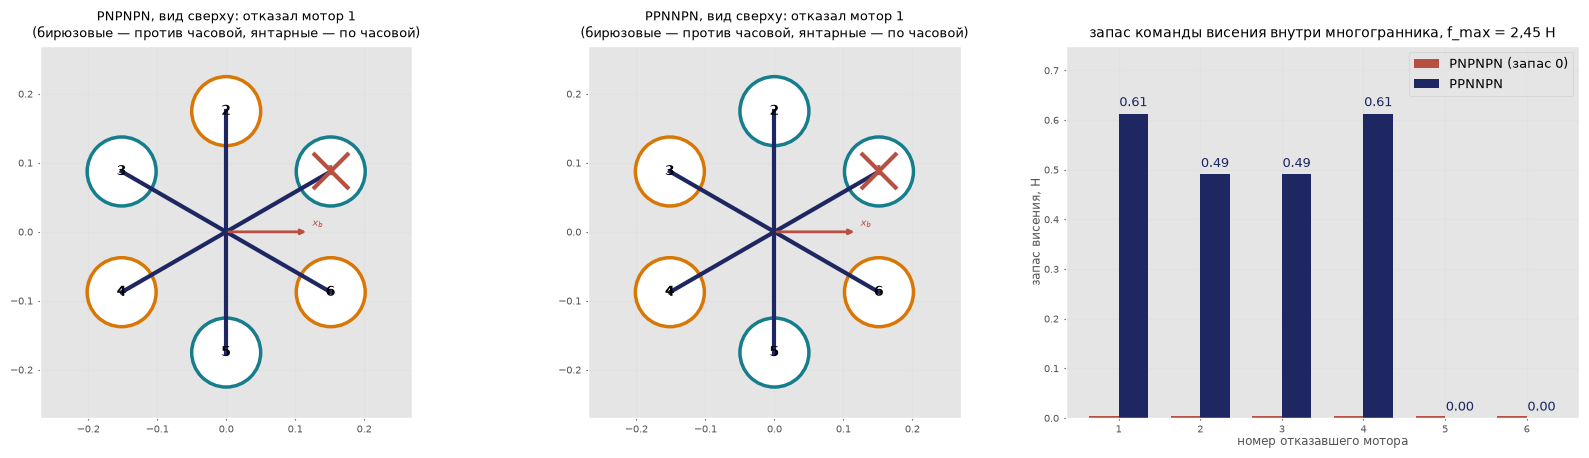

In [6]:
Mq = mixer_x(); W_ = M_Q*G; u_h = np.array([W_, 0, 0, 0.0])
nz = lambda x: round(float(x), 4) + 0.0          # запас без знака у «минус нуля» линейного программирования
print('КВАДРОКОПТЕР, отказ мотора 1:'); Mq1 = np.delete(Mq, 0, axis=1)
f3 = np.linalg.solve(Mq1[:3], u_h[:3])
print('  матрица 4×3, ранг %d;  висение со всеми четырьмя строками (τ_z = 0) достижимо: %s' % (np.linalg.matrix_rank(Mq1), hover_feasible(Mq1, W_, F_MAX)[0]))
print('  отказ от рыскания (строки T, τ_x, τ_y): f = (—; %.2f; %.2f; %.2f) Н -> мотор напротив (2) ВЫКЛЮЧЕН, моторы 3, 4 на пределе f_max = %.2f Н' % (*(f3 + 0.0), F_MAX))
print('  остаточный момент рыскания %.3f Н·м — аппарат вращается' % Mq1[3].dot(f3))
for fm in (2, 3, 6):
    print('  f_max = %d f_h: запас висения %.3f Н' % (fm, nz(hover_feasible(Mq1, W_, fm*F_HOVER, rows=(0, 1, 2))[2])))
rng = np.random.default_rng(0); bad = 0
for _ in range(1000):
    sol = np.linalg.solve(Mq1[:3], [W_, *rng.uniform(-0.05, 0.05, 2)]); bad += np.any(sol < -1e-12)
print('  1000 случайных малых запросов (τ_x, τ_y): требуют f_2 < 0 в %.1f %% случаев — недостижима полуплоскость τ_x + τ_y < 0' % (bad/10))

xy6, e6 = hexa_geometry(layout='PNPNPN'); Mh = mixer_general(xy6, e6)
from scipy.linalg import null_space
Nk = null_space(Mh)
print('\nГЕКСАКОПТЕР PNPNPN: ранг %d, ядро размерности %d; висение по M⁺: f =' % (np.linalg.matrix_rank(Mh), Nk.shape[1]), np.linalg.pinv(Mh).dot(u_h).round(4), 'Н')
print('  базис ядра (строки):\n', Nk.T.round(3), '\n  k_i = k_{i+3}: max|k_i − k_{i+3}| = %.1e' % np.abs(Nk[:3] - Nk[3:]).max())
for k in range(6):
    Mk = np.delete(Mh, k, axis=1); ok, fl, s = hover_feasible(Mk, W_, F_MAX); opp = (k + 3) % 6
    print('  отказ мотора %d: ранг %d; запас %.3f Н; тяга мотора напротив (%d) = %.3f Н -> мотор напротив выключен' % (k + 1, np.linalg.matrix_rank(Mk), nz(s), opp + 1, abs(fl[opp - (opp > k)])))
print('  отказ мотора 1, запас при f_max = 2,45 / 5 / 50 / 500 Н:', ['%.3f' % nz(hover_feasible(np.delete(Mh, 0, axis=1), W_, fm)[2]) for fm in (2.45, 5, 50, 500)], '-> 0 при любой f_max')
from scipy.optimize import linprog
Mk = np.delete(Mh, 0, axis=1); bad = 0
for _ in range(200):
    dd = rng.normal(size=3); dd = 0.01*dd/np.linalg.norm(dd)
    bad += not linprog(np.zeros(5), A_eq=Mk, b_eq=np.r_[W_, dd], bounds=[(0, 1000)]*5, method='highs').success
print('  200 малых добавок момента (|τ| = 0,01 Н·м) при f_max = 1000 Н: недостижимы %d — примерно половина' % bad)

xy6b, e6b = hexa_geometry(layout='PPNNPN'); Mh2 = mixer_general(xy6b, e6b)
marg = [nz(hover_feasible(np.delete(Mh2, k, axis=1), W_, F_MAX)[2]) for k in range(6)]
print('\nГЕКСАКОПТЕР PPNNPN (та же геометрия): запас висения при отказе моторов 1…6:', ['%.2f' % m_ for m_ in marg], 'Н')
print('  при отказе моторов 1–4 запас 0,49–0,61 Н, при отказе 5 или 6 — 0')

fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.6))
for ax, (xy_, e_, ttl) in zip(axs[:2], ((xy6, e6, 'PNPNPN'), (xy6b, e6b, 'PPNNPN'))):
    for i, (p_, s_) in enumerate(zip(xy_, e_)):
        ax.plot([0, p_[0]], [0, p_[1]], color=NAVY, lw=3); ax.add_patch(plt.Circle(p_, 0.05, fc='white', ec=TEAL if s_ > 0 else AMB, lw=2.5))
        ax.text(p_[0], p_[1], str(i + 1), ha='center', va='center', fontsize=10, color=RED if i == 0 else 'k', weight='bold')
    ax.plot(*xy_[0], 'x', color=RED, ms=26, mew=3); ax.annotate('', xy=(0.12, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=RED, lw=2)); ax.text(0.125, 0.008, '$x_b$', color=RED)
    ax.set_xlim(-0.27, 0.27); ax.set_ylim(-0.27, 0.27); ax.set_aspect('equal'); ax.grid(alpha=.3)
    ax.set_title('%s, вид сверху: отказал мотор 1\n(бирюзовые — против часовой, янтарные — по часовой)' % ttl, fontsize=9.5)
ax = axs[2]; k6 = np.arange(1, 7); ww = 0.36
ax.bar(k6 - ww/2, [nz(hover_feasible(np.delete(Mh, k, axis=1), W_, F_MAX)[2]) + 0.004 for k in range(6)], ww, color=RED, label='PNPNPN (запас 0)')
ax.bar(k6 + ww/2, marg, ww, color=NAVY, label='PPNNPN')
for i, m_ in enumerate(marg): ax.text(i + 1 + ww/2, m_ + 0.015, '%.2f' % m_, ha='center', fontsize=9, color=NAVY)
ax.set_xticks(k6); ax.set_xlabel('номер отказавшего мотора'); ax.set_ylabel('запас висения, Н'); ax.set_ylim(0, 0.75); ax.grid(alpha=.3); ax.legend(fontsize=9)
ax.set_title('запас команды висения внутри многогранника, f_max = 2,45 Н', fontsize=10)
plt.tight_layout(); plt.show()

## 6. Интерактив «наклон — ускорение» (§ 7.6)

Корпус удерживает высоту: $T(\mathbf z_b)_z=mg$, поэтому горизонтальное ускорение равно $g\,(z_{b,x},\,z_{b,y})/z_{b,z}$; в заголовке оно сравнивается с линеаризованной моделью $\ddot x=g(\theta c_\psi+\varphi s_\psi)$, $\ddot y=g(\theta s_\psi-\varphi c_\psi)$. Красная стрелка — тяга, янтарная — горизонтальное ускорение. Обратите внимание на знаки: положительный тангаж опускает нос и разгоняет вперёд, положительный крен опускает правый борт и уводит аппарат вправо, в сторону $-y_b$. Ожидаем (§ 7.6): наклон $10^{\circ}$ даёт $1{,}73$ м/с², наклон $30^{\circ}$ — $5{,}7$ м/с² при тяге, выросшей в $1{,}15$ раза; при $f_{\max}=2f_h$ предельный наклон без потери высоты $60^{\circ}$.

Сначала — статичный кадр для $\psi=30^{\circ}$, $\theta=15^{\circ}$, $\varphi=-10^{\circ}$ (он остаётся в сохранённом файле), затем ползунки (только при живом запуске).

наклон 10°: горизонтальное ускорение g·tg θ = 1.73 м/с², тяга должна вырасти в 1/cos θ = 1.02 раза
наклон 30°: горизонтальное ускорение g·tg θ = 5.66 м/с², тяга должна вырасти в 1/cos θ = 1.15 раза
наклон 60°: горизонтальное ускорение g·tg θ = 16.99 м/с², тяга должна вырасти в 1/cos θ = 2.00 раза
при f_max = 2 f_h предельный наклон без потери высоты arccos(1/2) = 60°


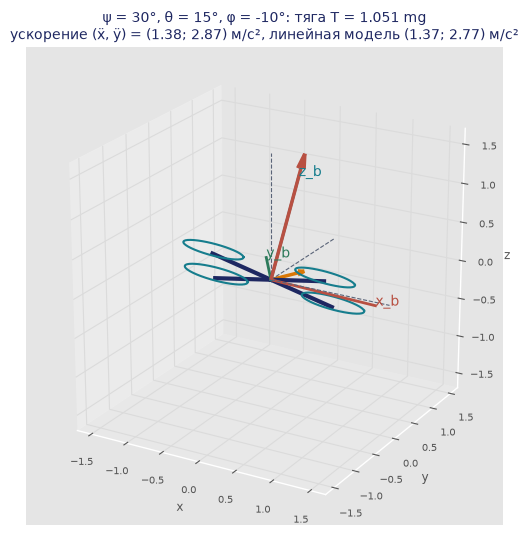

interactive(children=(FloatSlider(value=30.0, description='рыскание ψ', max=180.0, min=-180.0, step=5.0), Floa…

In [7]:
def show_quad(psi=0.0, theta=15.0, phi=0.0):
    R = R321(rad(psi), rad(theta), rad(phi)); zb = R[:, 2]
    fig = plt.figure(figsize=(6.8, 6.2)); ax = fig.add_subplot(111, projection='3d'); ax.view_init(22, -60)
    if zb[2] <= 0.05:
        draw_quad(ax, R); ax.set_title('ось тяги горизонтальна или направлена вниз: высоту не удержать', color=RED, fontsize=10)
    else:
        acc = G*zb[:2]/zb[2]; lin = G*np.array([rad(theta)*np.cos(rad(psi)) + rad(phi)*np.sin(rad(psi)), rad(theta)*np.sin(rad(psi)) - rad(phi)*np.cos(rad(psi))])
        draw_quad(ax, R, thrust=1.5/zb[2], accel=acc/G*1.5)
        ax.set_title('ψ = %.0f°, θ = %.0f°, φ = %.0f°: тяга T = %.3f mg\nускорение (ẍ, ÿ) = (%.2f; %.2f) м/с², линейная модель (%.2f; %.2f) м/с²'
                     % (psi, theta, phi, 1/zb[2], acc[0], acc[1], lin[0], lin[1]), fontsize=10, color=NAVY)
    plt.show()

for t_ in (10, 30, 60):
    print('наклон %2d°: горизонтальное ускорение g·tg θ = %.2f м/с², тяга должна вырасти в 1/cos θ = %.2f раза' % (t_, G*np.tan(rad(t_)), 1/np.cos(rad(t_))))
print('при f_max = 2 f_h предельный наклон без потери высоты arccos(1/2) = %.0f°' % deg(np.arccos(0.5)))
show_quad(30.0, 15.0, -10.0)       # статичный кадр
if interact is not None:
    interact(show_quad, psi=FloatSlider(min=-180, max=180, step=5, value=30.0, description='рыскание ψ'),
             theta=FloatSlider(min=-60, max=60, step=1, value=15.0, description='тангаж θ'), phi=FloatSlider(min=-60, max=60, step=1, value=-10.0, description='крен φ'))

## 7. Дифференциальная плоскостность на окружности (§ 7.6, пример 7.7, прил. 7.Б)

Плоские выходы $\boldsymbol\sigma=(x,y,z,\psi)$. По $\ddot{\mathbf p}$ и курсу: $\mathbf a_T=\ddot{\mathbf p}+g\mathbf z_0$, $T=m\lVert\mathbf a_T\rVert$, $\mathbf z_b=\mathbf a_T/\lVert\mathbf a_T\rVert$, $\mathbf x_b=\mathbf y_c\times\mathbf z_b/\lVert\cdot\rVert$, $\mathbf y_b=\mathbf z_b\times\mathbf x_b$. По рывку: $\mathbf h_\omega=\frac mT\bigl(\dddot{\mathbf p}-(\mathbf z_b\cdot\dddot{\mathbf p})\mathbf z_b\bigr)$, $\omega_x=-\mathbf h_\omega\cdot\mathbf y_b$, $\omega_y=\mathbf h_\omega\cdot\mathbf x_b$, $\omega_z=-s_\varphi\dot\theta+c_\varphi c_\theta\dot\psi$ (функция `flat_state`).

**Пример 7.7.** Окружность $\rho=2$ м, период 10 с, высота 1 м, $\psi=0$. Ожидаем: скорость 1,26 м/с, ускорение 0,79 м/с², наклон $4{,}6^{\circ}$ к центру, $T/mg=1{,}003$, $\theta^{\ast}=-0{,}080\cos0{,}628t$, $\varphi^{\ast}=0{,}080\sin0{,}628t$, рывок $0{,}50$ м/с³, при $t=1$ с $\boldsymbol\omega^b=(0{,}041;\ 0{,}030;\ -0{,}0014)$ рад/с — то же даёт численное дифференцирование $R(t)$: $\Lambda(\boldsymbol\omega^b)=R^{\mathrm T}\dot R$. Затем нос по касательной: $\mathbf z_b$ тот же, тангаж нулевой, крен постоянен и равен $-4{,}6^{\circ}$ (центр окружности слева, а положительный крен опускает правый борт). По желанию — сокращаем период до 5, 3 и 2,16 с: тяга одного мотора доходит до $f_{\max}$.

окружность: ω = 0.628 рад/с, скорость 1.26 м/с, ускорение 0.79 м/с², рывок 0.50 м/с³
t = 1 с: наклон оси тяги 4.60°, T/mg = 1.0032, dT/dt = 1.7e-18 Н/с
  углы: θ = -0.0650 рад (−0,080 cos 0,628t = -0.0651), φ = 0.0472 рад (0,080 sin 0,628t = 0.0473)
  ω^b по формулам плоскостности: [ 0.0408  0.0296 -0.0014] рад/с
  ω^b численно, (Rᵀ dR/dt)^∨:   [ 0.0408  0.0296 -0.0014] рад/с


  за весь период max|ω_формулы − ω_численно| = 4.2e-12 рад/с

нос по касательной (ψ = ωt + 90°):
  t = 0.0 с: ψ =    90.0°, θ = -0.000°, φ = -4.602°;  |z_b − z_b(ψ = 0)| = 0.0e+00
  t = 1.0 с: ψ =   126.0°, θ = -0.000°, φ = -4.602°;  |z_b − z_b(ψ = 0)| = 0.0e+00
  t = 3.3 с: ψ =  -151.2°, θ = -0.000°, φ = -4.602°;  |z_b − z_b(ψ = 0)| = 0.0e+00
  крен по модулю 4,6° и постоянен; знак минус: окружность обходится против часовой, центр слева, а положительный крен опускает правый борт

период | наклон | T/mg  | тяга мотора / f_max
10.00 с |   4.6° | 1.003 | 0.502
 5.00 с |  17.8° | 1.051 | 0.525
 3.00 с |  41.8° | 1.342 | 0.671
 2.16 с |  59.9° | 1.994 | 0.997


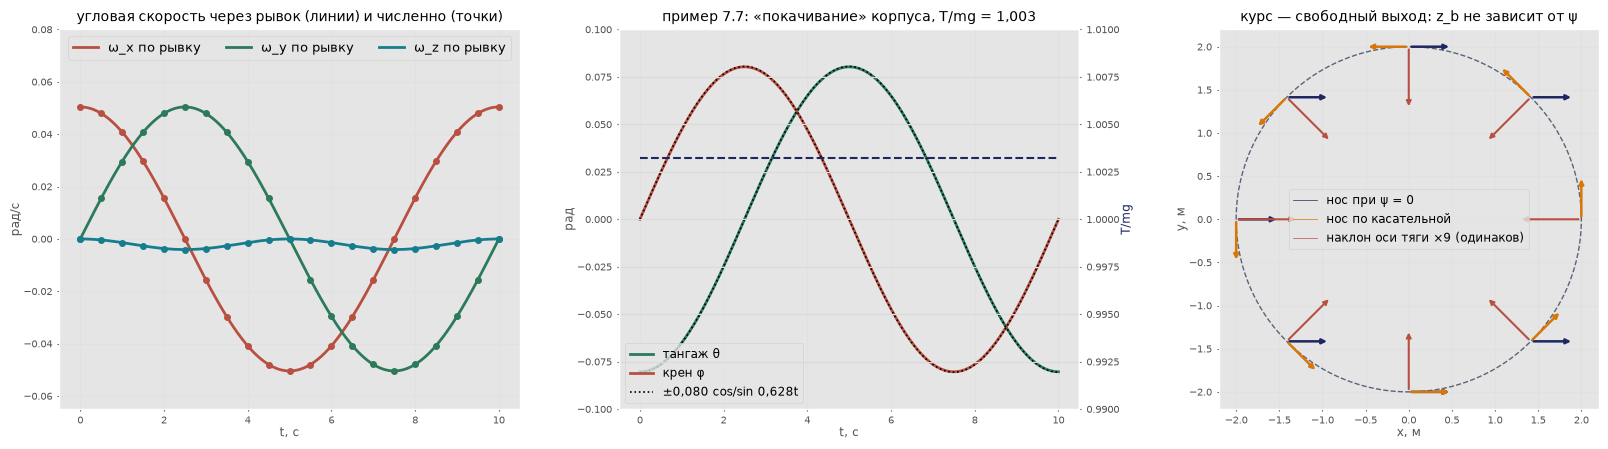

In [8]:
wc = 2*np.pi/10; tt = np.linspace(0, 10, 501); g_ = M_Q*G
p, v, a, j = circle_derivs(1.0)
print('окружность: ω = %.3f рад/с, скорость %.2f м/с, ускорение %.2f м/с², рывок %.2f м/с³' % (wc, np.linalg.norm(v), np.linalg.norm(a), np.linalg.norm(j)))
Rf, T1, dT1, w1 = flat_state(a, j, 0.0, 0.0)
print('t = 1 с: наклон оси тяги %.2f°, T/mg = %.4f, dT/dt = %.1e Н/с' % (deg(np.arccos(Rf[2, 2])), T1/g_, dT1))
ps1, th1, ph1 = euler321(Rf)
print('  углы: θ = %.4f рад (−0,080 cos 0,628t = %.4f), φ = %.4f рад (0,080 sin 0,628t = %.4f)' % (th1, -np.linalg.norm(a)/G*np.cos(wc), ph1, np.linalg.norm(a)/G*np.sin(wc)))
print('  ω^b по формулам плоскостности:', w1.round(4), 'рад/с')
h = 1e-5; Rp = flat_state(*circle_derivs(1.0 + h)[2:], 0, 0)[0]; Rm = flat_state(*circle_derivs(1.0 - h)[2:], 0, 0)[0]
print('  ω^b численно, (Rᵀ dR/dt)^∨:  ', vee(Rf.T.dot((Rp - Rm)/(2*h))).round(4), 'рад/с')
W_f = np.array([flat_state(*circle_derivs(t)[2:], 0, 0)[3] for t in tt])
W_n = np.array([vee(flat_state(*circle_derivs(t)[2:], 0, 0)[0].T.dot((flat_state(*circle_derivs(t + h)[2:], 0, 0)[0] - flat_state(*circle_derivs(t - h)[2:], 0, 0)[0])/(2*h))) for t in tt])
print('  за весь период max|ω_формулы − ω_численно| = %.1e рад/с' % np.abs(W_f - W_n).max())

print('\nнос по касательной (ψ = ωt + 90°):')
for t in (0.0, 1.0, 3.3):
    p_, v_, a_, j_ = circle_derivs(t); Rt = flat_state(a_, j_, wc*t + np.pi/2, wc)[0]; R0 = flat_state(a_, j_, 0.0, 0.0)[0]
    e_ = deg(np.array(euler321(Rt)))
    print('  t = %.1f с: ψ = %7.1f°, θ = %.3f°, φ = %.3f°;  |z_b − z_b(ψ = 0)| = %.1e' % (t, e_[0], e_[1], e_[2], np.abs(Rt[:, 2] - R0[:, 2]).max()))
print('  крен по модулю 4,6° и постоянен; знак минус: окружность обходится против часовой, центр слева, а положительный крен опускает правый борт')

print('\nпериод | наклон | T/mg  | тяга мотора / f_max')
for per in (10, 5, 3, 2.16):
    w_ = 2*np.pi/per; ac = w_**2*2.0; T_ = M_Q*np.hypot(ac, G)
    print('%5.2f с | %5.1f° | %.3f | %.3f' % (per, deg(np.arctan(ac/G)), T_/g_, T_/4/F_MAX))

Tt = np.array([flat_state(*circle_derivs(t)[2:], 0, 0)[1] for t in tt]); ang = np.array([euler321(flat_state(*circle_derivs(t)[2:], 0, 0)[0]) for t in tt])
fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.5)); ax = axs[0]
for k_, c, n_ in ((0, RED, 'ω_x'), (1, GREEN, 'ω_y'), (2, TEAL, 'ω_z')):
    ax.plot(tt, W_f[:, k_], color=c, lw=2, label=n_ + ' по рывку'); ax.plot(tt[::25], W_n[::25, k_], 'o', color=c, ms=4)
ax.grid(alpha=.3); ax.legend(fontsize=9, ncol=3, loc='upper center'); ax.set_xlabel('t, с'); ax.set_ylabel('рад/с'); ax.set_ylim(-0.065, 0.08)
ax.set_title('угловая скорость через рывок (линии) и численно (точки)', fontsize=10)
ax = axs[1]; ax.plot(tt, ang[:, 1], color=GREEN, lw=2, label='тангаж θ'); ax.plot(tt, ang[:, 2], color=RED, lw=2, label='крен φ')
ax.plot(tt, -0.0805*np.cos(wc*tt), ':', color='k', lw=1.2, label='±0,080 cos/sin 0,628t'); ax.plot(tt, 0.0805*np.sin(wc*tt), ':', color='k', lw=1.2)
ax2 = ax.twinx(); ax2.plot(tt, Tt/g_, color=NAVY, lw=1.5, ls='--'); ax2.set_ylim(0.99, 1.01); ax2.set_ylabel('T/mg', color=NAVY)
ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='lower left'); ax.set_xlabel('t, с'); ax.set_ylabel('рад'); ax.set_ylim(-0.1, 0.1)
ax.set_title('пример 7.7: «покачивание» корпуса, T/mg = 1,003', fontsize=10)
ax = axs[2]; ph_c = np.linspace(0, 2*np.pi, 200); ax.plot(2*np.cos(ph_c), 2*np.sin(ph_c), color=GREY, ls='--', lw=1)
for t in np.arange(0, 10, 1.25):
    p_, v_, a_, j_ = circle_derivs(t); R0 = flat_state(a_, j_, 0.0, 0.0)[0]; Rt = flat_state(a_, j_, wc*t + np.pi/2, wc)[0]
    ax.annotate('', xy=p_[:2] + 0.5*R0[:2, 0], xytext=p_[:2], arrowprops=dict(arrowstyle='-|>', color=NAVY, lw=1.8))
    ax.annotate('', xy=p_[:2] + 0.5*Rt[:2, 0], xytext=p_[:2], arrowprops=dict(arrowstyle='-|>', color=AMB, lw=1.8))
    ax.annotate('', xy=p_[:2] + 9*R0[:2, 2], xytext=p_[:2], arrowprops=dict(arrowstyle='-|>', color=RED, lw=1.5))
ax.plot([], [], color=NAVY, label='нос при ψ = 0'); ax.plot([], [], color=AMB, label='нос по касательной'); ax.plot([], [], color=RED, label='наклон оси тяги ×9 (одинаков)')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='center'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title('курс — свободный выход: z_b не зависит от ψ', fontsize=10)
plt.tight_layout(); plt.show()

## 8. Каскадное управление квадрокоптером (§ 7.6, пример 7.8)

**8а. Простой каскад (модель «наклон — ускорение»).** $\ddot{\mathbf p}_{\mathrm{cmd}}=\ddot{\mathbf p}^{\ast}+K_v(\dot{\mathbf p}^{\ast}-\dot{\mathbf p})+K_p(\mathbf p^{\ast}-\mathbf p)$, $K_p=2$ с$^{-2}$, $K_v=2{,}5$ с$^{-1}$; линейный пересчёт $\theta^{\ast}=(\ddot x_{\mathrm{cmd}}c_\psi+\ddot y_{\mathrm{cmd}}s_\psi)/g$, $\varphi^{\ast}=(\ddot x_{\mathrm{cmd}}s_\psi-\ddot y_{\mathrm{cmd}}c_\psi)/g$ с ограничением $20^{\circ}$; внутренние контуры заменены инерционным звеном с постоянной времени 0,15 с; корпус $m\ddot{\mathbf p}=-mg\mathbf z_0+TR\mathbf z_0$ (`simulate_quad`).
Ожидаем: на квадрате $4\times4$ м при 1 м/с наибольший угол по одной оси $11{,}5^{\circ}$, а полный наклон оси тяги $\arccos(\cos\varphi\cos\theta)$ — до $16{,}1^{\circ}$; на окружности примера 7.7 полный наклон около $4{,}6^{\circ}$, оси тяги смотрят к центру.

квадрат 4×4 м, 1 м/с: наибольший угол по одной оси 11.5°, полный наклон оси тяги до 16.1° (t = 4.29 с); наибольшая ошибка 0.48 м
окружность ρ = 2 м, 10 с: полный наклон в установившемся режиме 4.65°, ошибка слежения 0.033 м, радиус фактической траектории 2.020 м


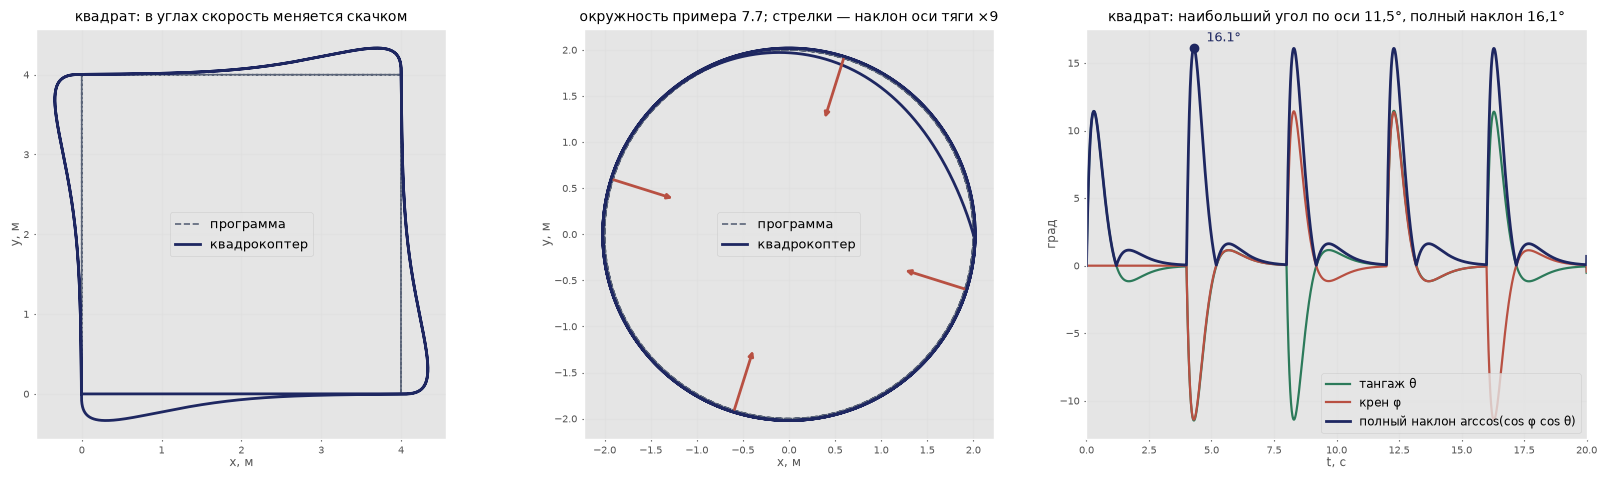

In [9]:
c = simulate_quad(ref_circle(2.0, 10.0), T=30.0); s = simulate_quad(ref_square(4.0, 1.0), T=32.0)
st = c['t'] > 10; i_t = np.argmax(s['tilt'])
print('квадрат 4×4 м, 1 м/с: наибольший угол по одной оси %.1f°, полный наклон оси тяги до %.1f° (t = %.2f с); наибольшая ошибка %.2f м'
      % (deg(max(np.abs(s['theta']).max(), np.abs(s['phi']).max())), deg(s['tilt'][i_t]), s['t'][i_t], np.linalg.norm((s['p'] - s['pref'])[:, :2], axis=1).max()))
print('окружность ρ = 2 м, 10 с: полный наклон в установившемся режиме %.2f°, ошибка слежения %.3f м, радиус фактической траектории %.3f м'
      % (deg(c['tilt'][st].mean()), np.linalg.norm((c['p'] - c['pref'])[st, :2], axis=1).max(), np.hypot(c['p'][st, 0], c['p'][st, 1]).mean()))

fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.8)); ax = axs[0]
ax.plot(s['pref'][:, 0], s['pref'][:, 1], color=GREY, ls='--', lw=1.2, label='программа'); ax.plot(s['p'][:, 0], s['p'][:, 1], color=NAVY, lw=2, label='квадрокоптер')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='center'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title('квадрат: в углах скорость меняется скачком', fontsize=10)
ax = axs[1]; ax.plot(c['pref'][:, 0], c['pref'][:, 1], color=GREY, ls='--', lw=1.2, label='программа'); ax.plot(c['p'][:, 0], c['p'][:, 1], color=NAVY, lw=2, label='квадрокоптер')
for tk in (12.0, 14.5, 17.0, 19.5):
    i = int(tk/0.005); zb = R321(0, c['theta'][i], c['phi'][i])[:, 2]
    ax.annotate('', xy=(c['p'][i, 0] + 9*zb[0], c['p'][i, 1] + 9*zb[1]), xytext=(c['p'][i, 0], c['p'][i, 1]), arrowprops=dict(arrowstyle='-|>', color=RED, lw=2))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='center'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title('окружность примера 7.7; стрелки — наклон оси тяги ×9', fontsize=10)
ax = axs[2]; ax.plot(s['t'], deg(s['theta']), color=GREEN, lw=1.6, label='тангаж θ'); ax.plot(s['t'], deg(s['phi']), color=RED, lw=1.6, label='крен φ')
ax.plot(s['t'], deg(s['tilt']), color=NAVY, lw=2, label='полный наклон arccos(cos φ cos θ)'); ax.plot(s['t'][i_t], deg(s['tilt'][i_t]), 'o', color=NAVY)
ax.text(s['t'][i_t] + 0.5, deg(s['tilt'][i_t]) + 0.5, '%.1f°' % deg(s['tilt'][i_t]), color=NAVY, fontsize=9)
ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='lower right'); ax.set_xlabel('t, с'); ax.set_ylabel('град'); ax.set_xlim(0, 20)
ax.set_title('квадрат: наибольший угол по оси 11,5°, полный наклон 16,1°', fontsize=10)
plt.tight_layout(); plt.show()

**8б. Пример 7.8: линейный и точный пересчёт ускорения в наклон.** $\ddot{\mathbf p}_{\mathrm{cmd}}=(5;\ 0;\ 0)$ м/с², $\psi=0$. Точный пересчёт (`thrust_vector`): $\mathbf a_T=(5;\,0;\,9{,}81)$, наклон $27{,}0^{\circ}$, тяга $5{,}51$ Н (на 12 % больше веса). Линейный (`accel_to_tilt`): $\theta^{\ast}=0{,}510$ рад $=29{,}2^{\circ}$, $T=mg=4{,}905$ Н, и аппарат получает $\ddot x=4{,}79$ м/с² и $\ddot z=-1{,}25$ м/с². При 7 м/с²: $35{,}5^{\circ}$ против $40{,}9^{\circ}$, проседание $2{,}4$ м/с².

**8в. Полный каскад** (`simulate_quad_full`): ПД по положению → точный пересчёт $\mathbf z_b^{\ast}=\mathbf a_T/\lVert\mathbf a_T\rVert$, $T=m\,\mathbf a_T\cdot\mathbf z_b$ (на **текущую** ось) и $R^{\ast}$ по курсу → П-регулятор ориентации по $\mathbf e_R=\frac12(R^{\ast\mathrm T}R-R^{\mathrm T}R^{\ast})^{\vee}$, $\boldsymbol\omega^{\ast}=-K_R\mathbf e_R$ → П-регулятор угловой скорости $\boldsymbol\tau=I K_\omega(\boldsymbol\omega^{\ast}-\boldsymbol\omega^b)+\boldsymbol\omega^b\times I\boldsymbol\omega^b$ → `allocate_priority` → тяги → твёрдое тело $I\dot{\boldsymbol\omega}^b=\boldsymbol\tau-\boldsymbol\omega^b\times I\boldsymbol\omega^b$, $R\leftarrow R\exp(\Delta t\,\Lambda(\boldsymbol\omega^b))$. Тензор инерции в лекции не задан; принято допущение порядка величины $I=\operatorname{diag}(2{,}5;\,2{,}5;\,4{,}5)\cdot10^{-3}$ кг·м² (не паспорт Hummingbird). Ожидаем: на тех же квадрате и окружности полный каскад повторяет простую модель — значит, инерционное звено 0,15 с было честной заменой быстрых внутренних контуров.

ẍ_cmd = 5 м/с²: точно — наклон 27.0°, T = 5.51 Н (112 % веса);  линейно — θ* = 0.510 рад = 29.2°, T = mg = 4.905 Н -> ẍ = 4.79, z̈ = -1.25 м/с²
ẍ_cmd = 7 м/с²: точно — наклон 35.5°, T = 6.03 Н (123 % веса);  линейно — θ* = 0.714 рад = 40.9°, T = mg = 4.905 Н -> ẍ = 6.42, z̈ = -2.39 м/с²



полный каскад, квадрат: ошибка до 0.47 м (простая модель 0.48 м), наибольший наклон 18.1° (простая 16.1°), ошибка высоты до 8.8 мм
полный каскад, окружность: ошибка слежения 0.028 м, наклон 4.64°, T/mg = 1.0033;  моторы в насыщении 0.0 % времени


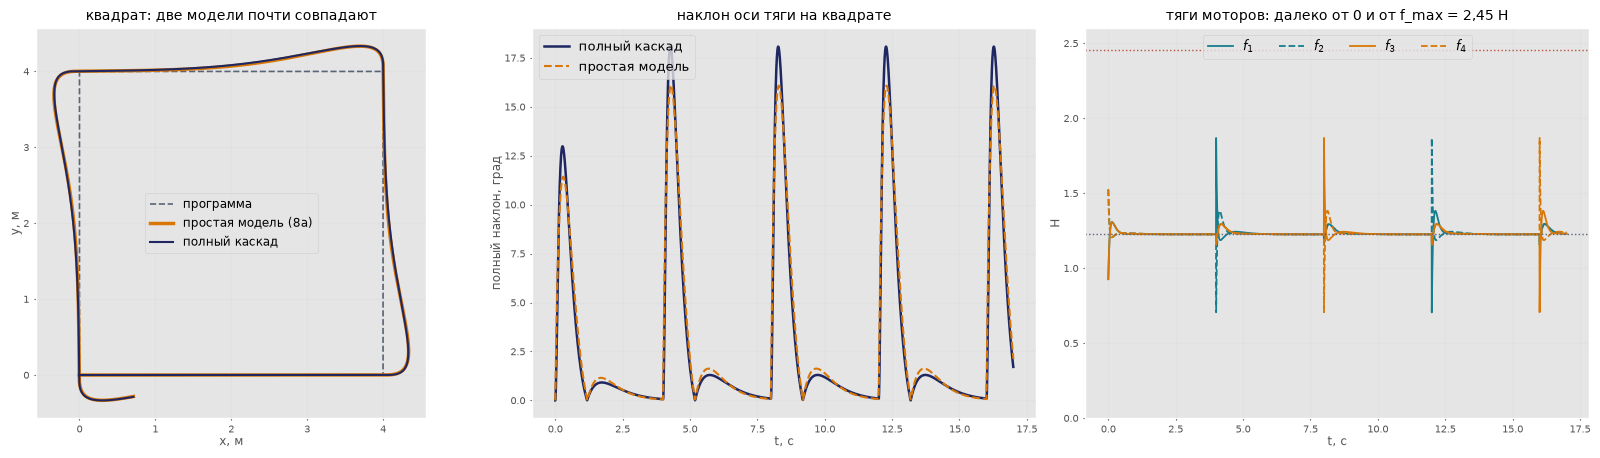

In [10]:
for acc_x in (5.0, 7.0):
    Rs, Ts, aT = thrust_vector([acc_x, 0, 0]); th_lin, _ = accel_to_tilt([acc_x, 0, 0])
    zb_lin = R321(0, th_lin, 0)[:, 2]; a_lin = M_Q*G/M_Q*zb_lin - np.array([0, 0, G])
    print('ẍ_cmd = %.0f м/с²: точно — наклон %.1f°, T = %.2f Н (%.0f %% веса);  линейно — θ* = %.3f рад = %.1f°, T = mg = %.3f Н -> ẍ = %.2f, z̈ = %.2f м/с²'
          % (acc_x, deg(np.arccos(Rs[2, 2])), Ts, 100*Ts/(M_Q*G), th_lin, deg(th_lin), M_Q*G, a_lin[0], a_lin[2]))

Fs = simulate_quad_full(ref_square(4.0, 1.0), T=17.0); Fc = simulate_quad_full(ref_circle(2.0, 10.0), T=15.0)
ss = s['t'] <= 17; stc = Fc['t'] > 10
print('\nполный каскад, квадрат: ошибка до %.2f м (простая модель %.2f м), наибольший наклон %.1f° (простая %.1f°), ошибка высоты до %.1f мм'
      % (np.linalg.norm((Fs['p'] - Fs['pref'])[:, :2], axis=1).max(), np.linalg.norm((s['p'] - s['pref'])[ss, :2], axis=1).max(), deg(Fs['tilt'].max()), deg(s['tilt'][ss].max()), 1000*np.abs(Fs['p'][:, 2] - 1).max()))
print('полный каскад, окружность: ошибка слежения %.3f м, наклон %.2f°, T/mg = %.4f;  моторы в насыщении %.1f %% времени'
      % (np.linalg.norm((Fc['p'] - Fc['pref'])[stc, :2], axis=1).max(), deg(Fc['tilt'][stc].mean()), (Fc['T'][stc]/(M_Q*G)).mean(), 100*Fs['sat'].mean()))

fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.6)); ax = axs[0]
ax.plot(Fs['pref'][:, 0], Fs['pref'][:, 1], color=GREY, ls='--', lw=1.2, label='программа')
ax.plot(s['p'][ss, 0], s['p'][ss, 1], color=AMB, lw=2.5, label='простая модель (8а)'); ax.plot(Fs['p'][:, 0], Fs['p'][:, 1], color=NAVY, lw=1.5, label='полный каскад')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='center'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_title('квадрат: две модели почти совпадают', fontsize=10)
ax = axs[1]; ax.plot(Fs['t'], deg(Fs['tilt']), color=NAVY, lw=1.8, label='полный каскад'); ax.plot(s['t'][ss], deg(s['tilt'][ss]), color=AMB, lw=1.5, ls='--', label='простая модель')
ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('t, с'); ax.set_ylabel('полный наклон, град'); ax.set_title('наклон оси тяги на квадрате', fontsize=10)
ax = axs[2]
for i_, c_ in enumerate((TEAL, TEAL, AMB, AMB)): ax.plot(Fs['t'], Fs['f'][:, i_], color=c_, lw=1.3, ls='-' if i_ % 2 == 0 else '--', label='$f_%d$' % (i_ + 1))
ax.axhline(F_HOVER, color=GREY, ls=':', lw=1); ax.axhline(F_MAX, color=RED, ls=':', lw=1); ax.set_ylim(0, 2.6)
ax.grid(alpha=.3); ax.legend(fontsize=9, ncol=4, loc='upper center'); ax.set_xlabel('t, с'); ax.set_ylabel('Н'); ax.set_title('тяги моторов: далеко от 0 и от f_max = 2,45 Н', fontsize=10)
plt.tight_layout(); plt.show()

**8г. Сломай и посмотри.** Четыре опыта, каждый меняет одно звено каскада.
1. **Нет разделения темпов.** В простой модели постоянная времени внутреннего контура 0,6 с вместо 0,15 с: внутренний контур уже не быстрее внешнего, траектория раскачивается и ошибка на квадрате растёт.
2. **Мало тяги и обрезание вместо приоритетов.** $f_{\max}=1{,}3f_h$; аппарат одновременно смещается на 2 м вбок и разворачивается на $90^{\circ}$. При обрезании пропадает запрошенный момент крена и проседает тяга, при приоритетах крен сохраняется, а разворот по курсу идёт медленнее.
3. **Перепутан знак $\kappa$ у одного мотора** (в «настоящей» матрице аппарата мотор 1 вращается по часовой стрелке, а распределитель считает, что против). Четвёртая строка $M$ неверна: возникает постоянный реактивный момент $2\kappa f_h\approx0{,}06$ Н·м, а рыскание отвечает на команду лишь вполовину; рыскание быстро упирается в предел и аппарат закручивается.
4. **Линейный пересчёт при больших наклонах.** Квадрат $8\times8$ м при 3 м/с с ограничением наклона $40^{\circ}$: линейные формулы с $T=m(g+\ddot z_{\mathrm{cmd}})$ дают проседание по высоте, точный пересчёт — нет.

1) τ = 0,6 с: наибольшая ошибка на квадрате 0.76 м (при τ = 0,15 с — 0.48 м)


2) f_max = 1,3 f_h, приоритеты: потеря момента крена до 0.000 Н·м, высота от 0.957 до 1.002 м, тяга от 0.93 до 1.04 mg, курс при t = 2 с 82.4°
2) f_max = 1,3 f_h, обрезание: потеря момента крена до 0.113 Н·м, высота от 0.854 до 1.000 м, тяга от 0.65 до 1.12 mg, курс при t = 2 с 85.8°
3) настоящая матрица: строка τ_z = [ 0.0245 -0.0245  0.0245  0.0245]  вместо [-0.0245 -0.0245  0.0245  0.0245] ; при равных тягах f_h реактивный момент 0.060 Н·м


   |ω_z| превышает 1 рад/с при t = 0.12 с, к t = 8 с ω_z = 5.8 рад/с; моторы в насыщении 89 % времени


4) квадрат 8×8 м, 3 м/с, точный   пересчёт: ошибка высоты до 0.05 м, наибольший наклон 39.8°
4) квадрат 8×8 м, 3 м/с, линейный пересчёт: ошибка высоты до 0.56 м, наибольший наклон 52.0°


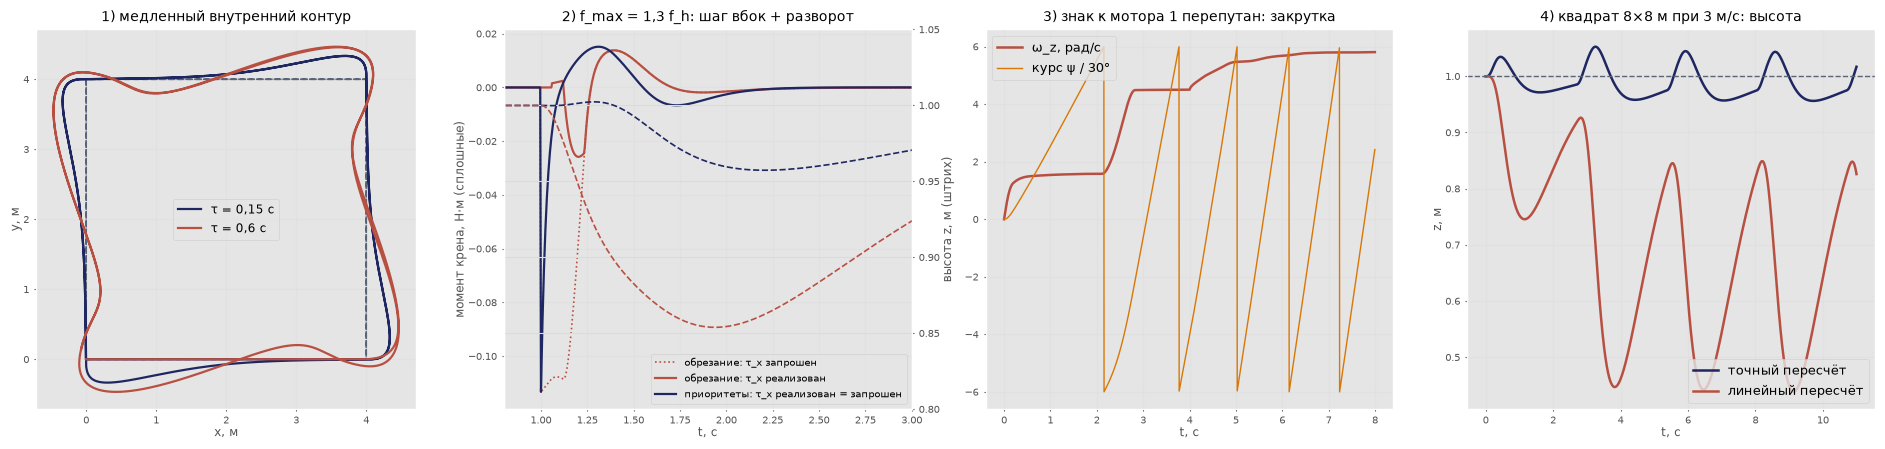

In [11]:
s6 = simulate_quad(ref_square(4.0, 1.0), T=32.0, tau=0.6)
print('1) τ = 0,6 с: наибольшая ошибка на квадрате %.2f м (при τ = 0,15 с — %.2f м)' % (np.linalg.norm((s6['p'] - s6['pref'])[:, :2], axis=1).max(), np.linalg.norm((s['p'] - s['pref'])[:, :2], axis=1).max()))

z3 = np.zeros(3)
ref_step = lambda t: (np.array([0.0, 0.0 if t < 1.0 else 2.0, 1.0]), z3, z3)
yaw_step = lambda t: 0.0 if t < 1.0 else rad(90.0)
runs = {al: simulate_quad_full(ref_step, T=4.0, fmax=1.3*F_HOVER, alloc=al, psi_ref=yaw_step) for al in ('priority', 'clip')}
for al, F in runs.items():
    i2 = int(round(2.0/0.004))
    print('2) f_max = 1,3 f_h, %-9s: потеря момента крена до %.3f Н·м, высота от %.3f до %.3f м, тяга от %.2f до %.2f mg, курс при t = 2 с %.1f°'
          % ('приоритеты' if al == 'priority' else 'обрезание', np.abs(F['tau_cmd'][:, 0] - F['tau_real'][:, 0]).max(), F['p'][:, 2].min(), F['p'][:, 2].max(), F['T'].min()/(M_Q*G), F['T'].max()/(M_Q*G), deg(F['psi'][i2])))

M_bad = mixer_x(eps=(-1, 1, -1, -1))
print('3) настоящая матрица: строка τ_z =', M_bad[3].round(4), ' вместо', mixer_x()[3].round(4), '; при равных тягах f_h реактивный момент %.3f Н·м' % M_bad[3].dot(np.full(4, F_HOVER)))
Fk = simulate_quad_full(ref_square(4.0, 1.0), T=8.0, M_plant=M_bad)
i_spin = np.argmax(np.abs(Fk['w'][:, 2]) > 1.0)
print('   |ω_z| превышает 1 рад/с при t = %.2f с, к t = 8 с ω_z = %.1f рад/с; моторы в насыщении %.0f %% времени' % (Fk['t'][i_spin], Fk['w'][-1, 2], 100*Fk['sat'].mean()))

sq3 = ref_square(8.0, 3.0); Fe = simulate_quad_full(sq3, T=11.0, tilt_max=rad(40), mapping='exact'); Fl = simulate_quad_full(sq3, T=11.0, tilt_max=rad(40), mapping='linear')
for n_, F in (('точный', Fe), ('линейный', Fl)):
    print('4) квадрат 8×8 м, 3 м/с, %-8s пересчёт: ошибка высоты до %.2f м, наибольший наклон %.1f°' % (n_, np.abs(F['p'][:, 2] - 1).max(), deg(F['tilt'].max())))

fig, axs = plt.subplots(1, 4, figsize=(19, 4.5)); ax = axs[0]
ax.plot(s['pref'][:, 0], s['pref'][:, 1], color=GREY, ls='--', lw=1.2); ax.plot(s['p'][:, 0], s['p'][:, 1], color=NAVY, lw=1.6, label='τ = 0,15 с')
ax.plot(s6['p'][:, 0], s6['p'][:, 1], color=RED, lw=1.6, label='τ = 0,6 с'); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='center')
ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_title('1) медленный внутренний контур', fontsize=10)
ax = axs[1]; tq = runs['clip']['t']
ax.plot(tq, runs['clip']['tau_cmd'][:, 0], color=RED, lw=1.2, ls=':', label='обрезание: τ_x запрошен')
ax.plot(tq, runs['clip']['tau_real'][:, 0], color=RED, lw=1.6, label='обрезание: τ_x реализован')
ax.plot(tq, runs['priority']['tau_real'][:, 0], color=NAVY, lw=1.6, label='приоритеты: τ_x реализован = запрошен')
ax3 = ax.twinx(); ax3.plot(tq, runs['priority']['p'][:, 2], color=NAVY, lw=1.2, ls='--'); ax3.plot(tq, runs['clip']['p'][:, 2], color=RED, lw=1.2, ls='--'); ax3.set_ylabel('высота z, м (штрих)'); ax3.set_ylim(0.8, 1.05)
ax.set_xlim(0.8, 3.0); ax.grid(alpha=.3); ax.legend(fontsize=7.5, loc='lower right'); ax.set_xlabel('t, с'); ax.set_ylabel('момент крена, Н·м (сплошные)'); ax.set_title('2) f_max = 1,3 f_h: шаг вбок + разворот', fontsize=10)
ax = axs[2]; ax.plot(Fk['t'], Fk['w'][:, 2], color=RED, lw=1.8, label='ω_z, рад/с'); ax.plot(Fk['t'], deg(Fk['psi'])/30, color=AMB, lw=1, label='курс ψ / 30°')
ax.grid(alpha=.3); ax.legend(fontsize=9, loc='upper left'); ax.set_xlabel('t, с'); ax.set_title('3) знак κ мотора 1 перепутан: закрутка', fontsize=10)
ax = axs[3]; ax.plot(Fe['t'], Fe['p'][:, 2], color=NAVY, lw=1.8, label='точный пересчёт'); ax.plot(Fl['t'], Fl['p'][:, 2], color=RED, lw=1.8, label='линейный пересчёт')
ax.axhline(1.0, color=GREY, ls='--', lw=1); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='lower right'); ax.set_xlabel('t, с'); ax.set_ylabel('z, м'); ax.set_title('4) квадрат 8×8 м при 3 м/с: высота', fontsize=10)
plt.tight_layout(); plt.show()

## 9. Самолёт: координированный разворот и снос ветром (§ 7.7, пример 7.9)

$\lvert\dot\psi\rvert=\dfrac gV\operatorname{tg}\lvert\varphi\rvert$, $\rho=\dfrac{V^2}{g\operatorname{tg}\lvert\varphi\rvert}$, перегрузка $1/\cos\varphi$; в наших осях $\dot\psi=-\dfrac gV\operatorname{tg}\varphi$ (положительный крен — разворот вправо, $\psi$ убывает). Ожидаем при $V=20$ м/с и $\varphi=30^{\circ}$: $\dot\psi=0{,}283$ рад/с $=16{,}2^{\circ}$/с, $\rho=70{,}6$ м, перегрузка $1{,}15$; при 40 м/с — 282 м.

**Пример 7.9.** Линия пути — ось $x$, $V_a=20$ м/с, ветер 6 м/с вдоль $y$: $V_a\sin\psi=-6$, курс $\psi=-17{,}5^{\circ}$, путевая скорость $V_g=19{,}1$ м/с; без поправки аппарат сносит на 6 м каждую секунду. Наконец, разворот с постоянным креном при ветре: относительно воздушной массы — окружность, относительно земли — трохоида, за один оборот её сносит на $6\cdot22{,}2\approx133$ м.

V = 20 м/с, крен 30°: |dψ/dt| = 0.283 рад/с = 16.2 °/с, ρ = 70.6 м, перегрузка 1/cos φ = 1.15
V = 40 м/с, крен 30°: |dψ/dt| = 8.1 °/с, ρ = 282 м (вчетверо больше)
знак в наших осях: крен +30° за 5 с изменил курс на -81.1° (−(g/V) tg φ · 5 с = -81.1°) — разворот вправо

Пример 7.9: курс с поправкой ψ = -17.5°, путевая скорость V_g = 19.1 м/с, угол сноса χ − ψ = 17.5°
  без поправки (ψ = 0): путевой угол 16.7°, путевая скорость 20.9 м/с, боковой снос 6 м/с · 30 с = 180 м
  разворот с креном 30° при ветре: оборот за 22.2 с; в воздушной массе траектория замыкается (невязка 0.06 м), над землёй её сносит на 133 м


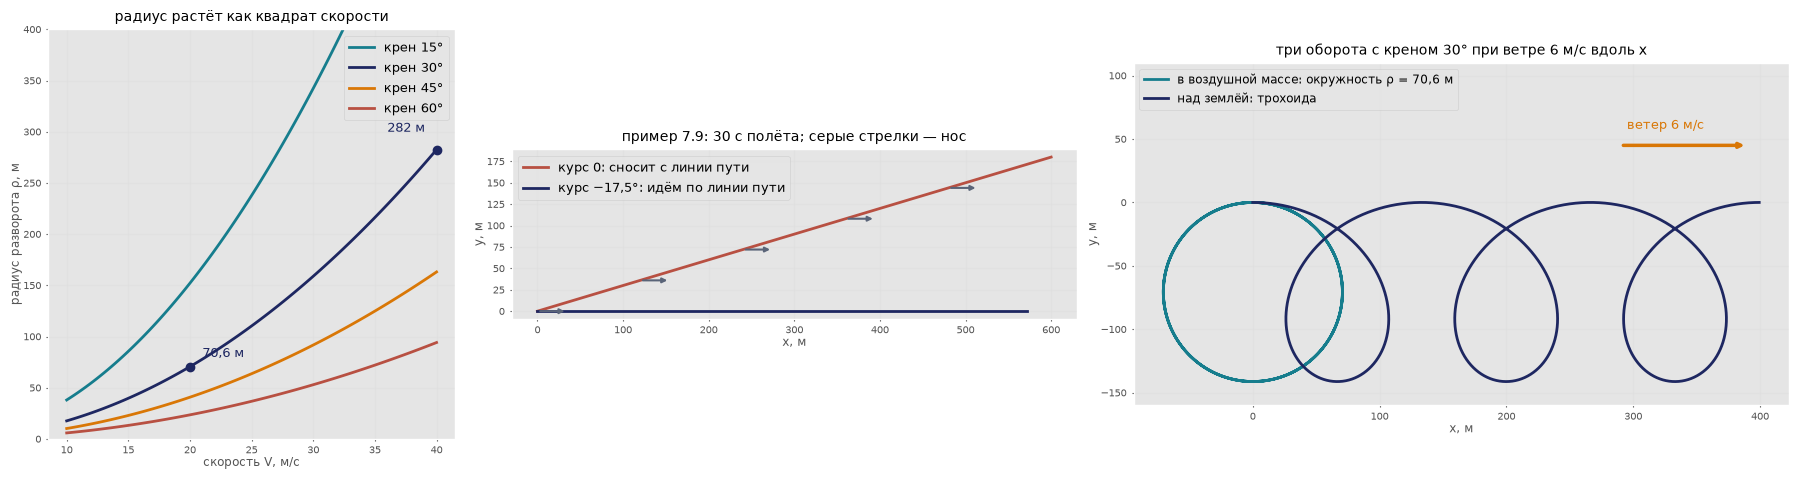

In [12]:
V, ph = 20.0, rad(30.0)
print('V = 20 м/с, крен 30°: |dψ/dt| = %.3f рад/с = %.1f °/с, ρ = %.1f м, перегрузка 1/cos φ = %.2f' % (turn_rate(V, ph), deg(turn_rate(V, ph)), turn_radius(V, ph), 1/np.cos(ph)))
print('V = 40 м/с, крен 30°: |dψ/dt| = %.1f °/с, ρ = %.0f м (вчетверо больше)' % (deg(turn_rate(40.0, ph)), turn_radius(40.0, ph)))
xy_b, xa_b, ps_b = simulate_bank(V, ph, T=5.0)
print('знак в наших осях: крен +30° за 5 с изменил курс на %.1f° (−(g/V) tg φ · 5 с = %.1f°) — разворот вправо' % (deg(ps_b[-1]), -deg(turn_rate(V, ph))*5))
Va, wind = 20.0, (0.0, 6.0); psi_c, Vg = crab_angle(Va, wind, chi=0.0)
print('\nПример 7.9: курс с поправкой ψ = %.1f°, путевая скорость V_g = %.1f м/с, угол сноса χ − ψ = %.1f°' % (deg(psi_c), Vg, -deg(psi_c)))
print('  без поправки (ψ = 0): путевой угол %.1f°, путевая скорость %.1f м/с, боковой снос 6 м/с · 30 с = %.0f м' % (deg(np.arctan2(6, 20)), np.hypot(20, 6), 6*30))
Tturn = 2*np.pi/turn_rate(V, ph); xy_g, xy_a, _ = simulate_bank(V, ph, wind=wind, T=Tturn)
print('  разворот с креном 30° при ветре: оборот за %.1f с; в воздушной массе траектория замыкается (невязка %.2f м), над землёй её сносит на %.0f м' % (Tturn, np.hypot(*(xy_a[-1] - xy_a[0])), np.hypot(*(xy_g[-1] - xy_g[0]))))

xy0 = simulate_plane(Va, lambda t, p: 0.0, wind, T=30); xy1 = simulate_plane(Va, lambda t, p: psi_c, wind, T=30)
xy_g3, xy_a3, _ = simulate_bank(V, ph, wind=(6.0, 0.0), T=3*Tturn)       # ветер вдоль x, чтобы трохоида легла горизонтально
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw=dict(width_ratios=[0.9, 1.25, 1.45])); vv = np.linspace(10, 40, 100); ax = axs[0]
for p_, c_ in ((15, TEAL), (30, NAVY), (45, AMB), (60, RED)): ax.plot(vv, turn_radius(vv, rad(p_)), color=c_, lw=2, label='крен %d°' % p_)
ax.plot([20, 40], [turn_radius(20, ph), turn_radius(40, ph)], 'o', color=NAVY); ax.text(21, 80, '70,6 м', color=NAVY, fontsize=9); ax.text(36, 300, '282 м', color=NAVY, fontsize=9)
ax.set_ylim(0, 400); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('скорость V, м/с'); ax.set_ylabel('радиус разворота ρ, м'); ax.set_title('радиус растёт как квадрат скорости', fontsize=10)
ax = axs[1]; ax.plot(xy0[:, 0], xy0[:, 1], color=RED, lw=2, label='курс 0: сносит с линии пути'); ax.plot(xy1[:, 0], xy1[:, 1], color=NAVY, lw=2, label='курс −17,5°: идём по линии пути')
for xy, ps in ((xy0, 0.0), (xy1, psi_c)):
    for i in range(0, len(xy), 120): ax.annotate('', xy=(xy[i, 0] + 35*np.cos(ps), xy[i, 1] + 35*np.sin(ps)), xytext=(xy[i, 0], xy[i, 1]), arrowprops=dict(arrowstyle='-|>', color=GREY, lw=1.5))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='upper left'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_title('пример 7.9: 30 с полёта; серые стрелки — нос', fontsize=10)
ax = axs[2]; ax.plot(xy_a3[:, 0], xy_a3[:, 1], color=TEAL, lw=2, label='в воздушной массе: окружность ρ = 70,6 м'); ax.plot(xy_g3[:, 0], xy_g3[:, 1], color=NAVY, lw=2, label='над землёй: трохоида')
ax.annotate('', xy=(390, 45), xytext=(290, 45), arrowprops=dict(arrowstyle='-|>', color=AMB, lw=2.5)); ax.text(295, 58, 'ветер 6 м/с', color=AMB, fontsize=9); ax.set_ylim(-160, 110)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper left'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_title('три оборота с креном 30° при ветре 6 м/с вдоль x', fontsize=10)
plt.tight_layout(); plt.show()

## 10. Пути Дубинса (§ 7.7, пример 7.10)

Модель: $\dot x=V\cos\psi$, $\dot y=V\sin\psi$, $\dot\psi=\omega_\psi$, $\lvert\omega_\psi\rvert\le V/\rho_{\min}$, $\rho_{\min}=70{,}6$ м. Перебираем шесть типов (LSL, RSR, LSR, RSL, RLR, LRL); каждый кандидат проверяется прямым построением (конец пути должен попасть в цель).
**Пример 7.10.** Далёкие позы $(0,0,0^{\circ})\to(400,250,180^{\circ})$: LSL 636 м — доворот на $15^{\circ}$, прямая 415 м, разворот на $165^{\circ}$; LSR 794, RSL 1080, RSR 1225 м; по прямой 472 м. Близкие позы $(0,0,90^{\circ})\to(90,0,-90^{\circ})$: LRL 395 м с правым разворотом на $250^{\circ}$, RSR 717 м. Сверка с `rtb.DubinsPlanner(curvature=1/70,6)`: длины $9{,}013\rho$ и $5{,}588\rho$, то есть 636 и 395 м. По желанию — перебор расстояния $D$ между точками во втором случае: тип кратчайшего пути меняется с LRL на RSR при $D\approx2\rho_{\min}$.

ρ_min при 20 м/с и 30° = 70.6 м

далёкие позы: по прямой 472 м
  LSL:   636.3 м = 9.013 ρ   (L 15°, S 415 м, L 165°)   <- кратчайший
  LSR:   793.7 м = 11.242 ρ   (L 49°, S 450 м, R 229°)
  RSL:  1079.5 м = 15.291 ρ   (R 345°, S 450 м, L 165°)
  RSR:  1224.9 м = 17.350 ρ   (R 316°, S 559 м, R 224°)

близкие позы: по прямой 90 м
  LRL:   394.5 м = 5.588 ρ   (L 35°, R 250°, L 35°)   <- кратчайший
  RLR:   613.9 м = 8.696 ρ   (R 80°, L 339°, R 80°)
  RSR:   716.6 м = 10.150 ρ   (R 270°, S 51 м, R 270°)
  LSL:   896.6 м = 12.700 ρ   (L 270°, S 231 м, L 270°)

rtb.DubinsPlanner, далёкие позы: LSL, длина 9.013 ρ = 636.3 м (aerial: LSL, 636.3 м)

rtb.DubinsPlanner, близкие позы: LRL, длина 5.588 ρ = 394.5 м (aerial: LRL, 394.5 м)



перебор D (старт (0, 0, 90°), цель (D, 0, −90°)): смена типа кратчайшего пути LRL -> RSR при D = 142 м (2ρ_min = 141 м)


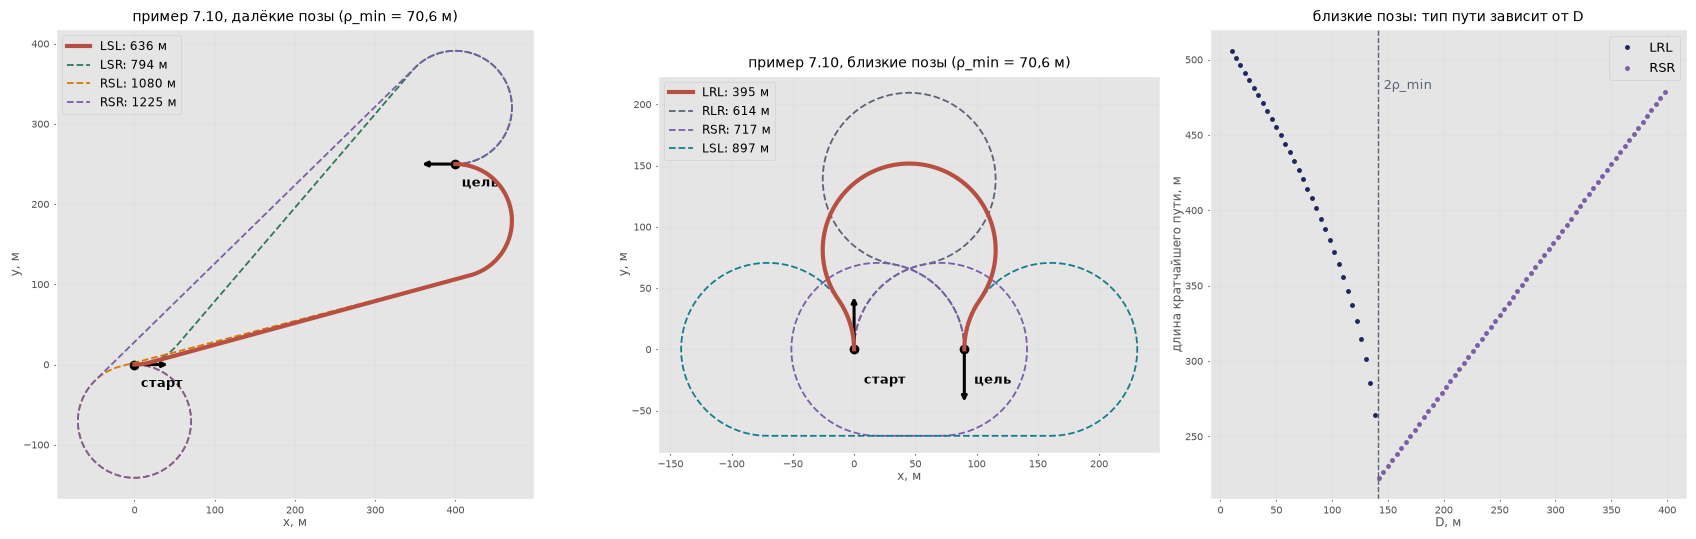

In [13]:
rho = 70.6
print('ρ_min при 20 м/с и 30° = %.1f м' % turn_radius(20.0, rad(30.0)))
cases = [((0.0, 0.0, 0.0), (400.0, 250.0, np.pi), 'далёкие позы'), ((0.0, 0.0, np.pi/2), (90.0, 0.0, -np.pi/2), 'близкие позы')]
cols = {'LSL': TEAL, 'RSR': '#7B5EA7', 'LSR': GREEN, 'RSL': AMB, 'RLR': GREY, 'LRL': NAVY}
best = []
fig, axs = plt.subplots(1, 3, figsize=(17.5, 5.4), gridspec_kw=dict(width_ratios=[1.25, 1, 0.95]))
for ax, (st, go, ttl) in zip(axs, cases):
    paths = dubins_all(st, go, rho); best.append(paths[0]); print('\n%s: по прямой %.0f м' % (ttl, np.hypot(go[0] - st[0], go[1] - st[1])))
    for j, (Ln, wn, segs, xs, ys) in enumerate(paths):
        parts = ', '.join(('%s %.0f°' % (ch, deg(s_))) if ch != 'S' else ('S %.0f м' % (s_*rho)) for ch, s_ in zip(wn, segs))
        print('  %s: %7.1f м = %.3f ρ   (%s)%s' % (wn, Ln, Ln/rho, parts, '   <- кратчайший' if j == 0 else ''))
        ax.plot(xs, ys, color=RED if j == 0 else cols[wn], lw=3 if j == 0 else 1.3, ls='-' if j == 0 else '--', zorder=6 if j == 0 else 3, label='%s: %.0f м' % (wn, Ln))
    for pose, n_ in ((st, 'старт'), (go, 'цель')):
        ax.annotate('', xy=(pose[0] + 45*np.cos(pose[2]), pose[1] + 45*np.sin(pose[2])), xytext=pose[:2], arrowprops=dict(arrowstyle='-|>', color='k', lw=2.2)); ax.plot(pose[0], pose[1], 'ko')
        ax.text(pose[0] + 8, pose[1] - 28, n_, fontsize=9.5, weight='bold')
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper left'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_title('пример 7.10, %s (ρ_min = 70,6 м)' % ttl, fontsize=10)
if rtb is not None:
    dp = rtb.DubinsPlanner(curvature=1/rho)
    for (st, go, ttl), b in zip(cases, best):
        path, status = dp.query(start=st, goal=go)
        print('\nrtb.DubinsPlanner, %s: %s, длина %.3f ρ = %.1f м (aerial: %s, %.1f м)' % (ttl, ''.join(status.segments), status.length, status.length*rho, b[1], b[0]))
DD = np.arange(10, 400.1, 4.0); Lb = []; Wb = []
for D in DD:
    r_ = dubins_all((0, 0, np.pi/2), (D, 0, -np.pi/2), rho)[0]; Lb.append(r_[0]); Wb.append(r_[1])
sw = [i for i in range(1, len(DD)) if Wb[i] != Wb[i-1]]
print('\nперебор D (старт (0, 0, 90°), цель (D, 0, −90°)): смена типа кратчайшего пути', ', '.join('%s -> %s при D = %.0f м' % (Wb[i-1], Wb[i], DD[i]) for i in sw), '(2ρ_min = %.0f м)' % (2*rho))
ax = axs[2]
for wn in sorted(set(Wb)):
    m_ = np.array([w_ == wn for w_ in Wb]); ax.plot(DD[m_], np.array(Lb)[m_], '.', color=cols[wn], ms=5, label=wn)
ax.axvline(2*rho, color=GREY, ls='--', lw=1); ax.text(2*rho + 5, max(Lb)*0.95, '2ρ_min', color=GREY, fontsize=9)
ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('D, м'); ax.set_ylabel('длина кратчайшего пути, м'); ax.set_title('близкие позы: тип пути зависит от D', fontsize=10)
plt.tight_layout(); plt.show()

## 11. Оценка ориентации (§ 7.8, пример 7.11)

Модель гироскопа $\omega_{\mathrm m}=\omega+b+\nu$. **Пример 7.11.** Смещение нуля $b=0{,}01$ рад/с, аппарат висит: чистое интегрирование даёт за 60 с ошибку $0{,}6$ рад $=34^{\circ}$, а у БИНС через проекцию $g$ — ошибку положения $gbt^3/6\approx16$ м уже за 10 с. Угол по акселерометру не дрейфует, но зашумлён (здесь шум $2^{\circ}$). Комплементарный фильтр $\hat\theta_{k+1}=a(\hat\theta_k+\Delta t\,\omega_{y,k})+(1-a)\theta_{\mathrm{acc},k}$ при $a=0{,}98$, $\Delta t=0{,}01$ с: постоянная времени $a\Delta t/(1-a)=0{,}49$ с, остаточная ошибка $a\Delta t\,b/(1-a)=0{,}0049$ рад $=0{,}28^{\circ}$ — она не растёт (те же данные, что на рис. 7.13: `complementary_pitch` с параметрами по умолчанию).

Отдельно: на окружности примера 7.7 корпус наклонён на $4{,}6^{\circ}$, а акселерометр $\mathbf a_{\mathrm m}=R^{\mathrm T}\mathbf a_T$ показывает ровно $(0;\,0;\,T/m)$ — он «не видит» наклон в манёвре. По желанию — фильтр Махони на $SO(3)$ с оценкой смещения (`mahony_hover`): ошибка наклона не растёт, а оценка $\hat b_y$ сходится к 0,01 рад/с. Коэффициент $k_P$ измеряется в с$^{-1}$ и соответствует $1/\tau=(1-a)/(a\Delta t)$ одномерного фильтра (при $a=0{,}98$ — около 2 с$^{-1}$); здесь взято $k_P=1$ с$^{-1}$.

чистое интегрирование гироскопа за 60 с: 34.3° (b·t = 0,6 рад = 34.4°)
комплементарный фильтр a = 0,98: τ = 0.49 с, остаточная ошибка a Δt b/(1 − a) = 0.0049 рад = 0.28°
  в расчёте с шумами: средняя ошибка за 10–60 с 0.27°, разброс 0.21°;  угол по акселерометру — шум 2.0°
  без шумов: ошибка фильтра к 60 с = 0.281°

окружность примера 7.7: наклон корпуса 4.60°, акселерометр R^T a_T = [-0.      0.      9.8417] м/с², T/m = 9.8417 м/с²
  тангаж «по акселерометру» = 0.00°, истинный тангаж = -3.73°
БИНС: смещение b = 0,01 рад/с за 10 с даёт ошибку положения g b t³/6 = 16.4 м



фильтр Махони (k_P = 1, k_I = 0,1): ошибка наклона к 60 с 0.39° (чистый гироскоп 34.4°), оценка смещения b̂ = [ 0.0005  0.0101 -0.    ] рад/с


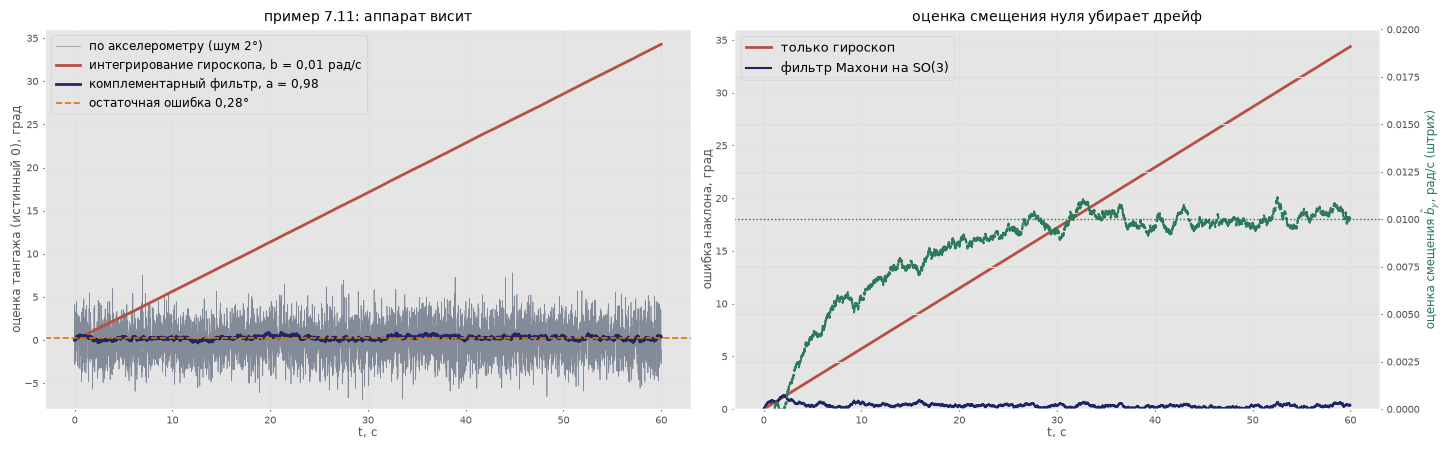

In [14]:
cf = complementary_pitch(); st = cf['t'] > 10
print('чистое интегрирование гироскопа за 60 с: %.1f° (b·t = 0,6 рад = %.1f°)' % (deg(cf['gyro_int'][-1]), deg(0.6)))
print('комплементарный фильтр a = 0,98: τ = %.2f с, остаточная ошибка a Δt b/(1 − a) = %.4f рад = %.2f°' % (cf['tau'], cf['resid'], deg(cf['resid'])))
print('  в расчёте с шумами: средняя ошибка за 10–60 с %.2f°, разброс %.2f°;  угол по акселерометру — шум %.1f°' % (deg(cf['filt'][st].mean()), deg(cf['filt'][st].std()), deg(cf['acc'].std())))
cf0 = complementary_pitch(gyro_noise=0.0, acc_noise=0.0); print('  без шумов: ошибка фильтра к 60 с = %.3f°' % deg(cf0['filt'][-1]))

p, v, a, j = circle_derivs(1.0); Rc, Tc, _, _ = flat_state(a, j, 0.0, 0.0)
print('\nокружность примера 7.7: наклон корпуса %.2f°, акселерометр R^T a_T =' % deg(np.arccos(Rc[2, 2])), Rc.T.dot(a + np.array([0, 0, G])).round(4), 'м/с², T/m = %.4f м/с²' % (Tc/M_Q))
th_acc = np.arctan2(-Rc.T.dot(a + [0, 0, G])[0], Rc.T.dot(a + [0, 0, G])[2])
print('  тангаж «по акселерометру» = %.2f°, истинный тангаж = %.2f°' % (deg(th_acc), deg(euler321(Rc)[1])))

print('БИНС: смещение b = 0,01 рад/с за 10 с даёт ошибку положения g b t³/6 = %.1f м' % (G*0.01*10**3/6))

mh = mahony_hover()
print('\nфильтр Махони (k_P = 1, k_I = 0,1): ошибка наклона к 60 с %.2f° (чистый гироскоп %.1f°), оценка смещения b̂ =' % (mh['tilt_err'][-1], mh['tilt_err_gyro'][-1]), mh['b_hat'][-1].round(4), 'рад/с')

fig, axs = plt.subplots(1, 2, figsize=(14.5, 4.5)); ax = axs[0]
ax.plot(cf['t'], deg(cf['acc']), color=GREY, lw=0.5, alpha=.7, label='по акселерометру (шум 2°)'); ax.plot(cf['t'], deg(cf['gyro_int']), color=RED, lw=2, label='интегрирование гироскопа, b = 0,01 рад/с')
ax.plot(cf['t'], deg(cf['filt']), color=NAVY, lw=2, label='комплементарный фильтр, a = 0,98'); ax.axhline(deg(cf['resid']), color=AMB, ls='--', lw=1.2, label='остаточная ошибка 0,28°')
ax.set_ylim(-8, 36); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper left'); ax.set_xlabel('t, с'); ax.set_ylabel('оценка тангажа (истинный 0), град'); ax.set_title('пример 7.11: аппарат висит', fontsize=10)
ax = axs[1]; ax.plot(mh['t'], mh['tilt_err_gyro'], color=RED, lw=2, label='только гироскоп'); ax.plot(mh['t'], mh['tilt_err'], color=NAVY, lw=1.5, label='фильтр Махони на SO(3)')
ax2 = ax.twinx(); ax2.plot(mh['t'], mh['b_hat'][:, 1], color=GREEN, lw=1.5, ls='--'); ax2.axhline(0.01, color=GREEN, ls=':', lw=1); ax2.set_ylabel('оценка смещения $\\hat b_y$, рад/с (штрих)', color=GREEN); ax2.set_ylim(0, 0.02)
ax.set_ylim(0, 36); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='upper left'); ax.set_xlabel('t, с'); ax.set_ylabel('ошибка наклона, град'); ax.set_title('оценка смещения нуля убирает дрейф', fontsize=10)
plt.tight_layout(); plt.show()